In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


RESULTS_DIR = "../results/2026-06-25_full_benchmark"
METRICS_DIR = os.path.join(RESULTS_DIR, "metrics")
PREDICTIONS_DIR = os.path.join(RESULTS_DIR, "predictions")
SUMMARY_PATH = os.path.join(
    RESULTS_DIR,
    "summaries",
    "all_models_all_series_summary.csv"
)

FIGURE_DIR = "../figures/benchmark_v1_refined"
os.makedirs(FIGURE_DIR, exist_ok=True)

MODEL_ORDER = [
    "naive",
    "drift_naive",
    "ar1",
    "xgboost_level",
    "xgboost_increment",
    "lstm_level",
    "lstm_increment",
    "gru_level",
    "tcn_level",
    "simple_causal_transformer",
    "residual_causal_transformer",
    "causal_encoder_transformer",
    "patchtst_level"
]

SERIES_ORDER = [
    "linear_gaussian",
    "linear_student_t",
    "nonlinear_gaussian",
    "nonlinear_student_t"
]

TOP_MODELS = [
    "naive",
    "drift_naive",
    "xgboost_increment",
    "lstm_increment",
    "tcn_level",
    "residual_causal_transformer"
]

COLLAPSE_THRESHOLD = 1.0

In [2]:
def model_label(name):
    return name.replace("_", " ").title()


def load_all_metrics():
    files = glob.glob(os.path.join(METRICS_DIR, "*_metrics.csv"))
    dfs = []

    for file in files:
        df = pd.read_csv(file)
        dfs.append(df)

    return pd.concat(dfs, ignore_index=True)


metrics_df = load_all_metrics()
summary_df = pd.read_csv(SUMMARY_PATH)

metrics_df.head(), summary_df.head()

(      sigma  n_samples       rmse  rmse_over_sigma  directional_accuracy  \
 0  1.555556        496   2.181205         1.402203              0.498990   
 1  1.777778        500   2.432330         1.368186              0.482966   
 2  2.000000        500   2.892125         1.446062              0.472946   
 3  1.555556        496  14.158985         9.102205              0.492929   
 4  1.777778        500   8.766517         4.931166              0.529058   
 
                         model           series  collapse_sigma  
 0                         ar1  linear_gaussian        1.555556  
 1                         ar1  linear_gaussian        1.555556  
 2                         ar1  linear_gaussian        1.555556  
 3  causal_encoder_transformer  linear_gaussian        1.555556  
 4  causal_encoder_transformer  linear_gaussian        1.555556  ,
             series              model      collapse_sigma collapse_status  \
 0  linear_gaussian              naive               > 2.0   

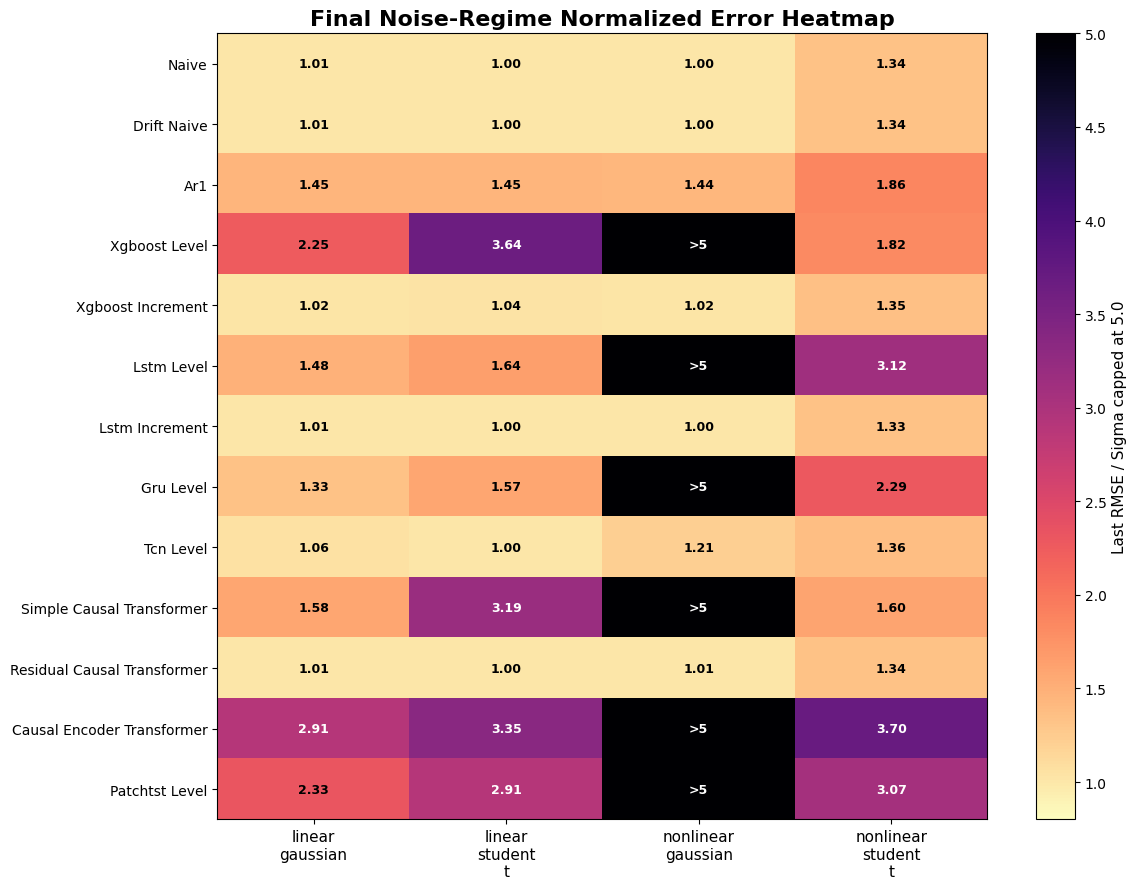

../figures/benchmark_v1_refined\refined_last_rmse_over_sigma_heatmap.png


In [3]:
heatmap_df = summary_df.pivot(
    index="model",
    columns="series",
    values="last_rmse_over_sigma"
).reindex(MODEL_ORDER)

# Cap extreme values so good models remain visually distinguishable.
CAP_VALUE = 5.0
heatmap_capped = heatmap_df.clip(upper=CAP_VALUE)

plt.figure(figsize=(12, 9))

im = plt.imshow(
    heatmap_capped.values,
    aspect="auto",
    cmap="magma_r",
    vmin=0.8,
    vmax=CAP_VALUE
)

plt.xticks(
    ticks=np.arange(len(heatmap_capped.columns)),
    labels=[s.replace("_", "\n") for s in heatmap_capped.columns],
    rotation=0,
    fontsize=11
)

plt.yticks(
    ticks=np.arange(len(heatmap_capped.index)),
    labels=[model_label(m) for m in heatmap_capped.index],
    fontsize=10
)

cbar = plt.colorbar(im)
cbar.set_label("Last RMSE / Sigma capped at 5.0", fontsize=11)

for i in range(heatmap_df.shape[0]):
    for j in range(heatmap_df.shape[1]):
        raw_value = heatmap_df.values[i, j]

        if raw_value > CAP_VALUE:
            text = f">{CAP_VALUE:.0f}"
        else:
            text = f"{raw_value:.2f}"

        text_color = "white" if heatmap_capped.values[i, j] > 2.7 else "black"

        plt.text(
            j,
            i,
            text,
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold",
            color=text_color
        )

plt.title(
    "Final Noise-Regime Normalized Error Heatmap",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

path = os.path.join(FIGURE_DIR, "refined_last_rmse_over_sigma_heatmap.png")
plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(path)

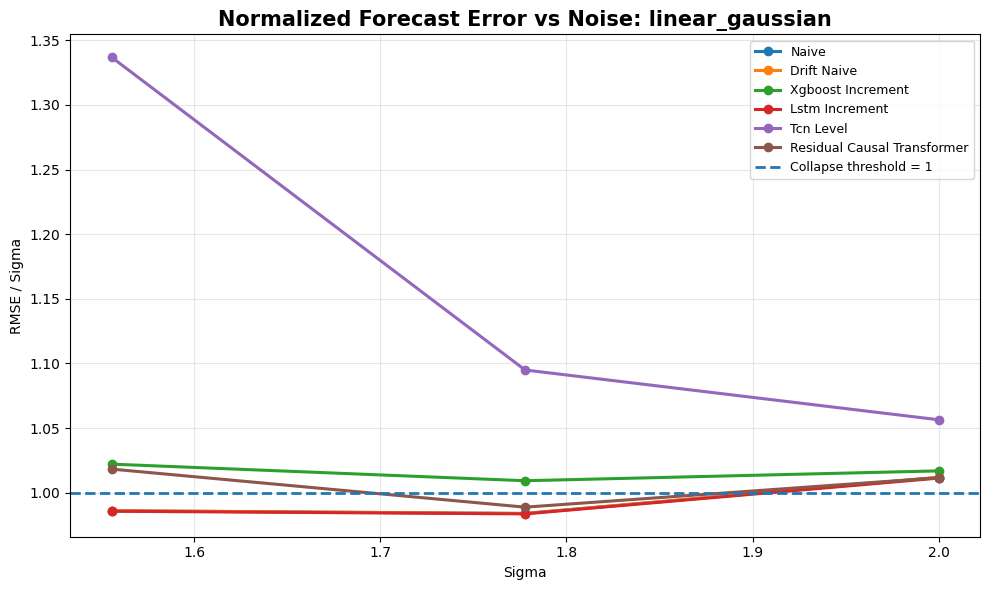

../figures/benchmark_v1_refined\refined_linear_gaussian_rmse_over_sigma_top_models.png


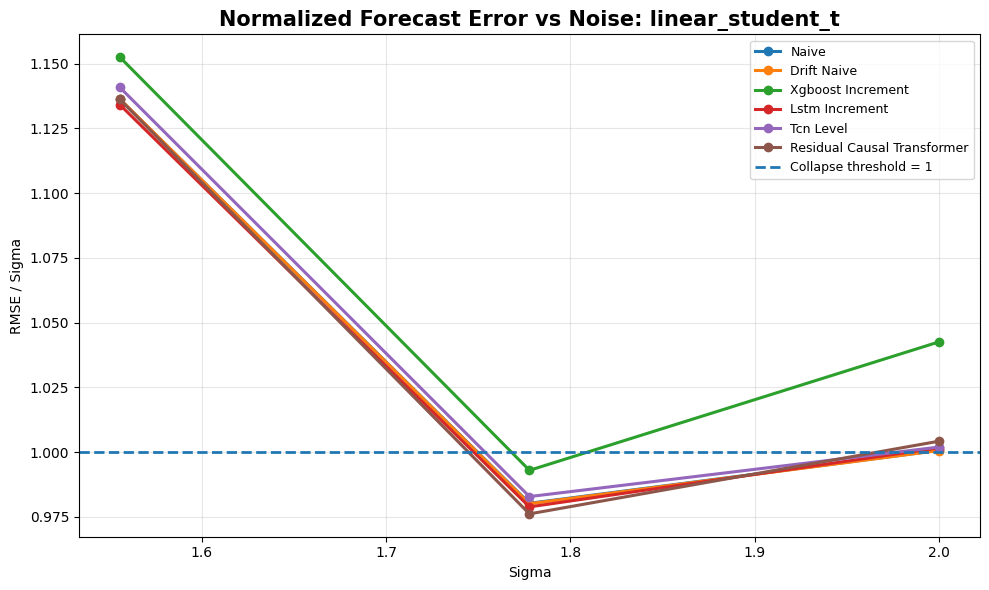

../figures/benchmark_v1_refined\refined_linear_student_t_rmse_over_sigma_top_models.png


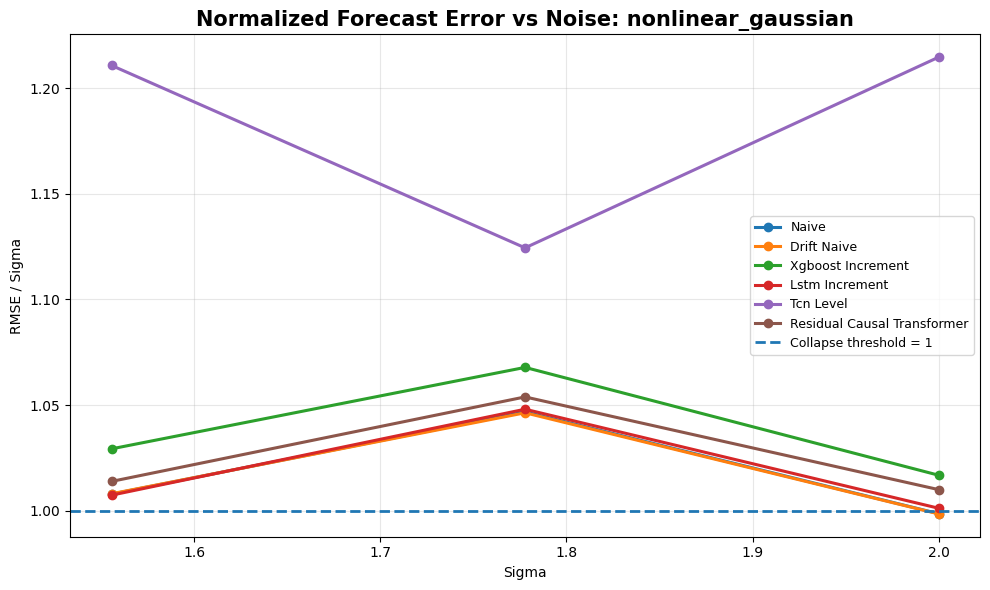

../figures/benchmark_v1_refined\refined_nonlinear_gaussian_rmse_over_sigma_top_models.png


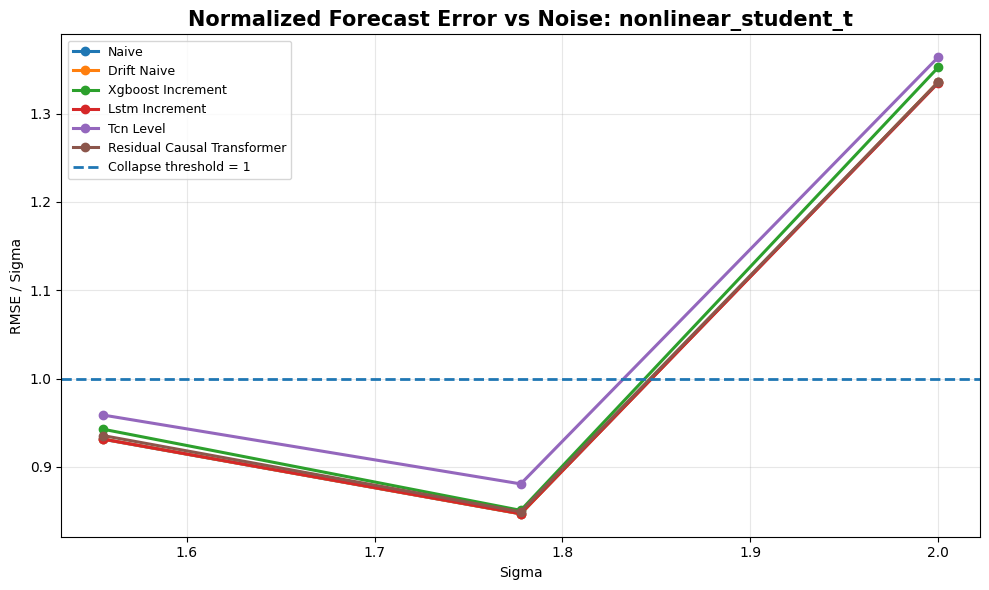

../figures/benchmark_v1_refined\refined_nonlinear_student_t_rmse_over_sigma_top_models.png


In [4]:
for series in SERIES_ORDER:

    subset = metrics_df[metrics_df["series"] == series]

    plt.figure(figsize=(10, 6))

    for model in TOP_MODELS:
        temp = subset[subset["model"] == model].sort_values("sigma")

        if temp.empty:
            continue

        plt.plot(
            temp["sigma"],
            temp["rmse_over_sigma"],
            marker="o",
            linewidth=2.2,
            label=model_label(model)
        )

    plt.axhline(
        COLLAPSE_THRESHOLD,
        linestyle="--",
        linewidth=2,
        label="Collapse threshold = 1"
    )

    plt.title(
        f"Normalized Forecast Error vs Noise: {series}",
        fontsize=15,
        fontweight="bold"
    )
    plt.xlabel("Sigma")
    plt.ylabel("RMSE / Sigma")
    plt.grid(True, alpha=0.3)
    plt.legend(fontsize=9)
    plt.tight_layout()

    path = os.path.join(
        FIGURE_DIR,
        f"refined_{series}_rmse_over_sigma_top_models.png"
    )

    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()

    print(path)

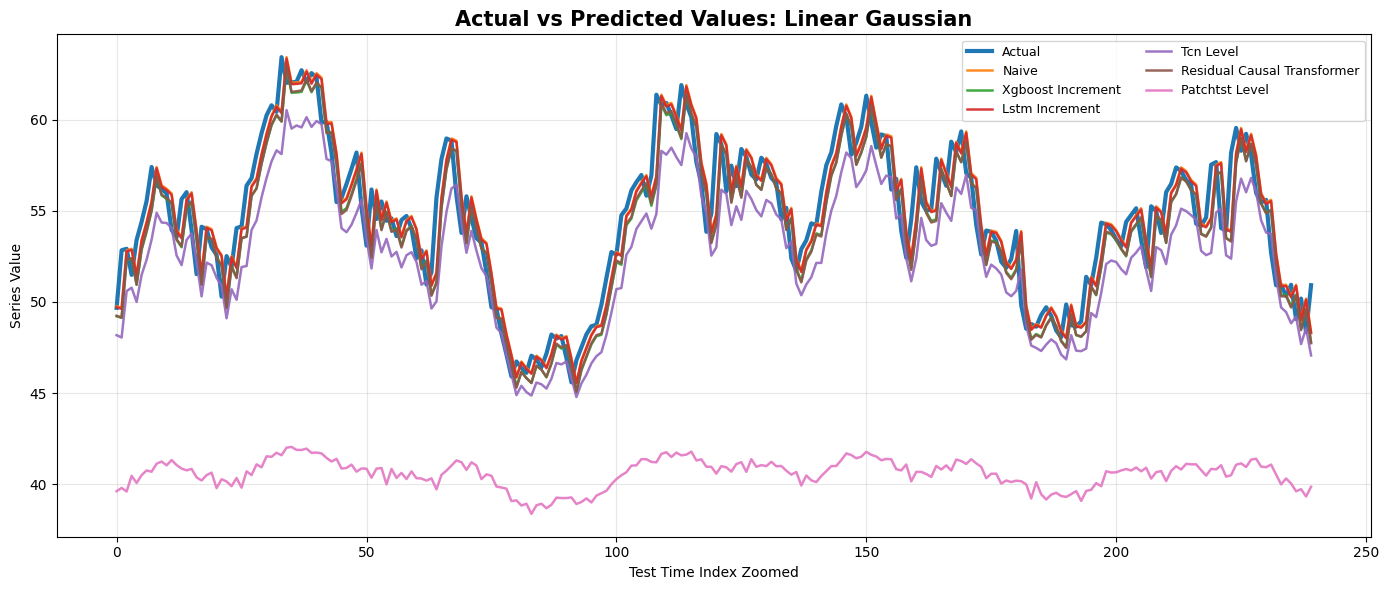

../figures/benchmark_v1_refined\refined_zoomed_prediction_examples_linear_gaussian.png


In [20]:
EXAMPLE_SERIES = "linear_gaussian"

EXAMPLE_MODELS = [
    "naive",
    "xgboost_increment",
    "lstm_increment",
    "tcn_level",
    "residual_causal_transformer",
    "patchtst_level"
]

START = 120
END = 360

plt.figure(figsize=(14, 6))

for model in EXAMPLE_MODELS:

    file_path = os.path.join(
        PREDICTIONS_DIR,
        f"{EXAMPLE_SERIES}_{model}_predictions.csv"
    )

    if not os.path.exists(file_path):
        continue

    pred_df = pd.read_csv(file_path)

    if model == "naive":
        plt.plot(
            pred_df["y_true"].values[START:END],
            linewidth=3,
            label="Actual"
        )

    plt.plot(
        pred_df["y_pred"].values[START:END],
        linewidth=1.8,
        alpha=0.9,
        label=model_label(model)
    )

plt.title(
    "Actual vs Predicted Values: Linear Gaussian",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Test Time Index Zoomed")
plt.ylabel("Series Value")
plt.grid(True, alpha=0.3)
plt.legend(fontsize=9, ncol=2)
plt.tight_layout()

path = os.path.join(
    FIGURE_DIR,
    "refined_zoomed_prediction_examples_linear_gaussian.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(path)

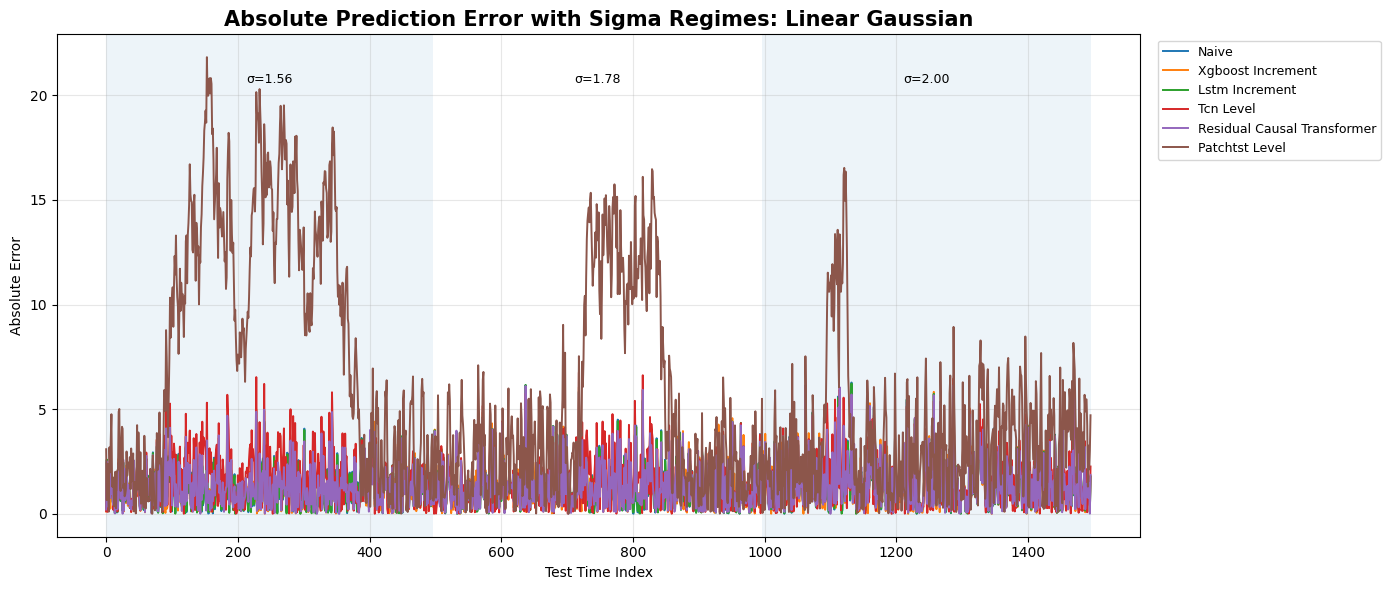

../figures/benchmark_v1_refined\refined_error_vs_time_with_sigma_regimes_linear_gaussian.png


In [21]:
EXAMPLE_SERIES = "linear_gaussian"

plt.figure(figsize=(18, 6))

for model in EXAMPLE_MODELS:

    file_path = os.path.join(
        PREDICTIONS_DIR,
        f"{EXAMPLE_SERIES}_{model}_predictions.csv"
    )

    if not os.path.exists(file_path):
        continue

    pred_df = pd.read_csv(file_path)

    abs_error = np.abs(pred_df["y_true"] - pred_df["y_pred"])

    plt.plot(
        abs_error.values,
        linewidth=1.4,
        label=model_label(model)
    )

# Sigma regime shading
ref_path = os.path.join(
    PREDICTIONS_DIR,
    f"{EXAMPLE_SERIES}_naive_predictions.csv"
)

ref_df = pd.read_csv(ref_path)
sigma_values = ref_df["sigma"].values

change_points = [0]

for i in range(1, len(sigma_values)):
    if sigma_values[i] != sigma_values[i - 1]:
        change_points.append(i)

change_points.append(len(sigma_values))

for idx in range(len(change_points) - 1):
    start = change_points[idx]
    end = change_points[idx + 1]
    sigma = sigma_values[start]

    if idx % 2 == 0:
        plt.axvspan(start, end, alpha=0.08)

    mid = (start + end) / 2
    ymax = plt.ylim()[1]

    plt.text(
        mid,
        ymax * 0.92,
        f"σ={sigma:.2f}",
        ha="center",
        va="top",
        fontsize=9
    )

plt.title(
    "Absolute Prediction Error with Sigma Regimes: Linear Gaussian",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Test Time Index")
plt.ylabel("Absolute Error")
plt.grid(True, alpha=0.3)
#plt.legend(loc='center right', fontsize=9, ncol=2)
#plt.tight_layout()

plt.legend(
    fontsize=9,
    ncol=1,
    loc="upper left",
    bbox_to_anchor=(1.01, 1.0),
    frameon=True
)

plt.tight_layout(rect=[0, 0, 0.78, 1])


path = os.path.join(
    FIGURE_DIR,
    "refined_error_vs_time_with_sigma_regimes_linear_gaussian.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(path)

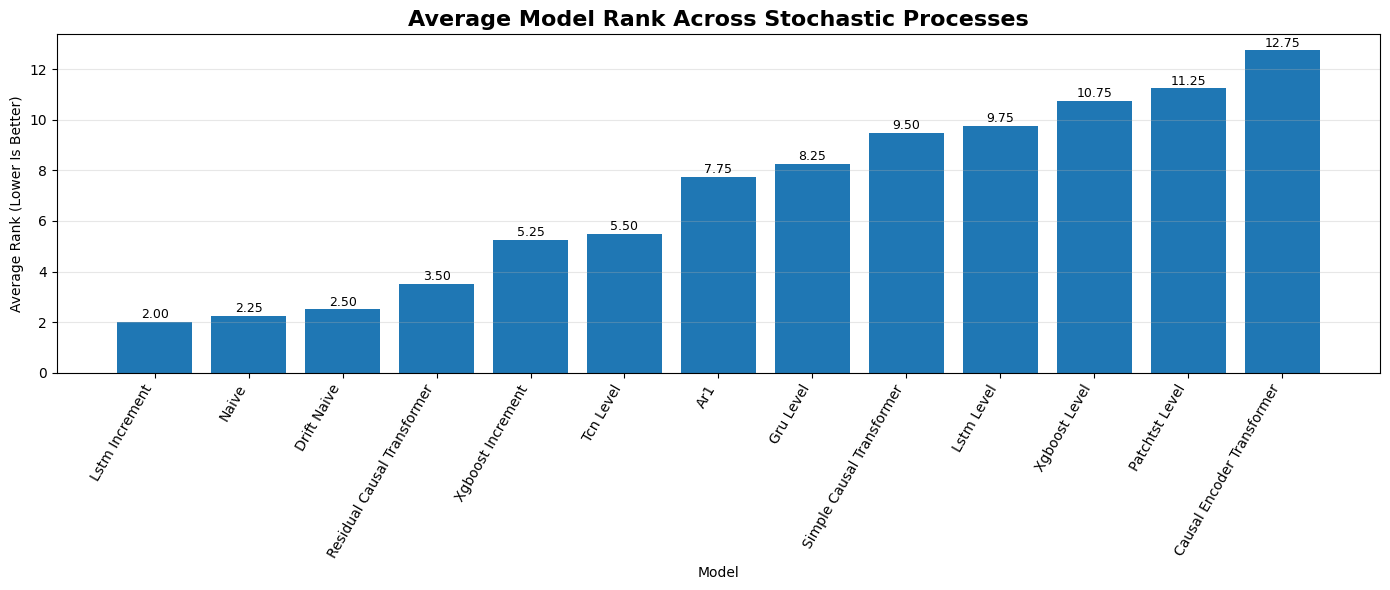

../figures/benchmark_v1_refined\refined_average_model_rank.png


In [16]:
rank_df = summary_df.copy()

rank_df["rank"] = rank_df.groupby("series")["last_rmse_over_sigma"].rank(
    method="average",
    ascending=True
)

avg_rank = (
    rank_df.groupby("model")["rank"]
    .mean()
    .reindex(MODEL_ORDER)
    .sort_values()
)

plt.figure(figsize=(14, 6))

bars = plt.bar(
    [model_label(m) for m in avg_rank.index],
    avg_rank.values
)

for bar, value in zip(bars, avg_rank.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.15,
        f"{value:.2f}",
        ha="center",
        fontsize=9
    )

plt.title(
    "Average Model Rank Across Stochastic Processes",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Model")
plt.ylabel("Average Rank (Lower Is Better)")
plt.xticks(rotation=60, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

path = os.path.join(FIGURE_DIR, "refined_average_model_rank.png")

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(path)

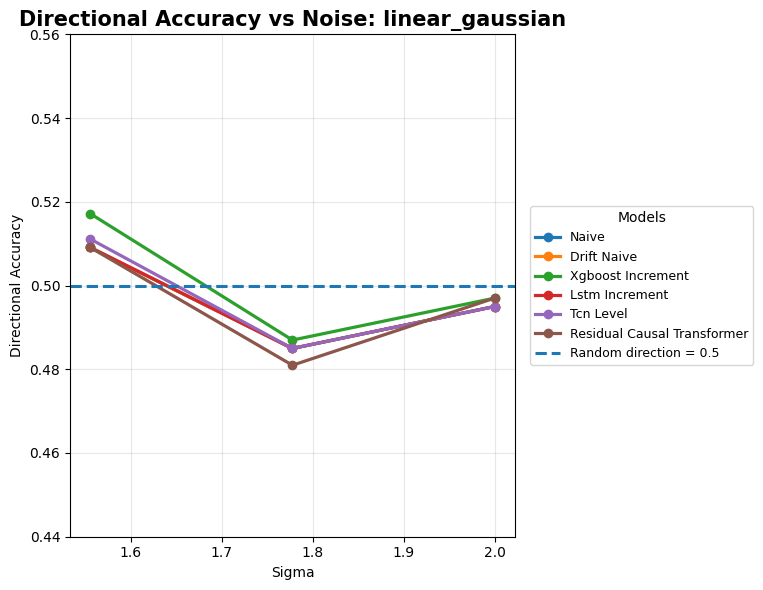

../figures/benchmark_v1_refined\refined_linear_gaussian_directional_accuracy_top_models.png


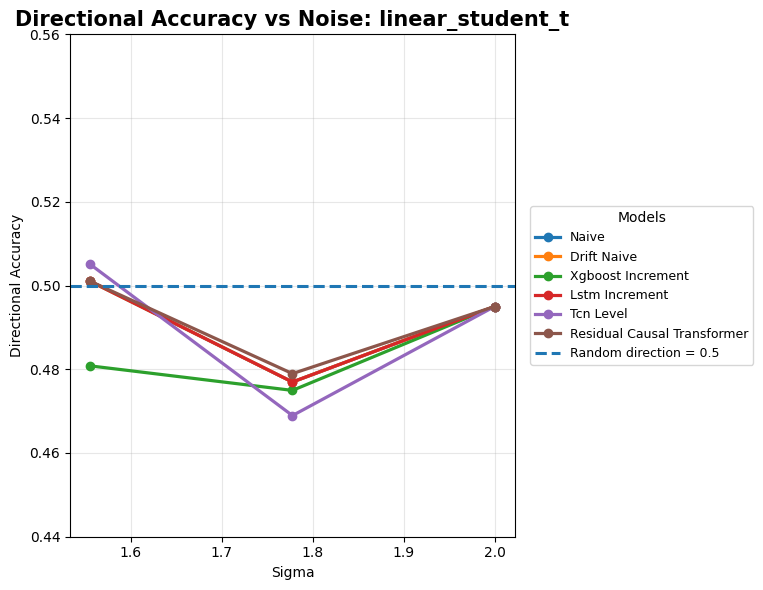

../figures/benchmark_v1_refined\refined_linear_student_t_directional_accuracy_top_models.png


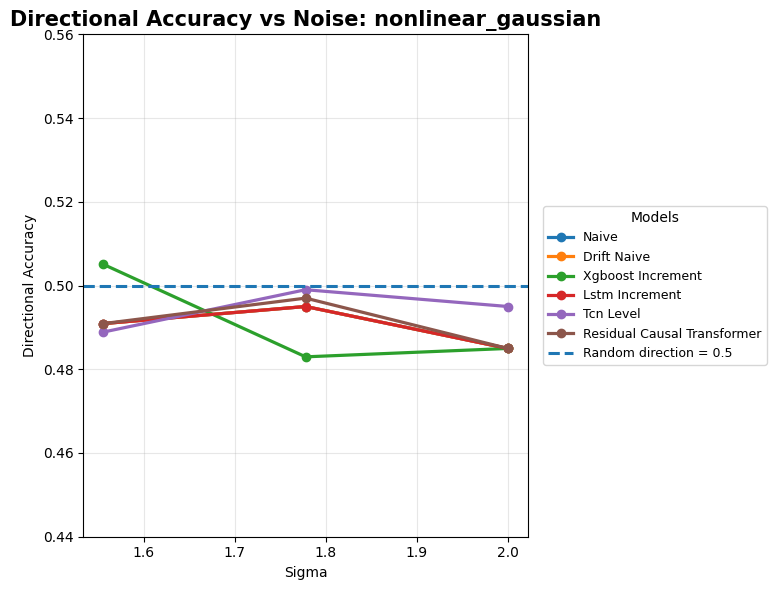

../figures/benchmark_v1_refined\refined_nonlinear_gaussian_directional_accuracy_top_models.png


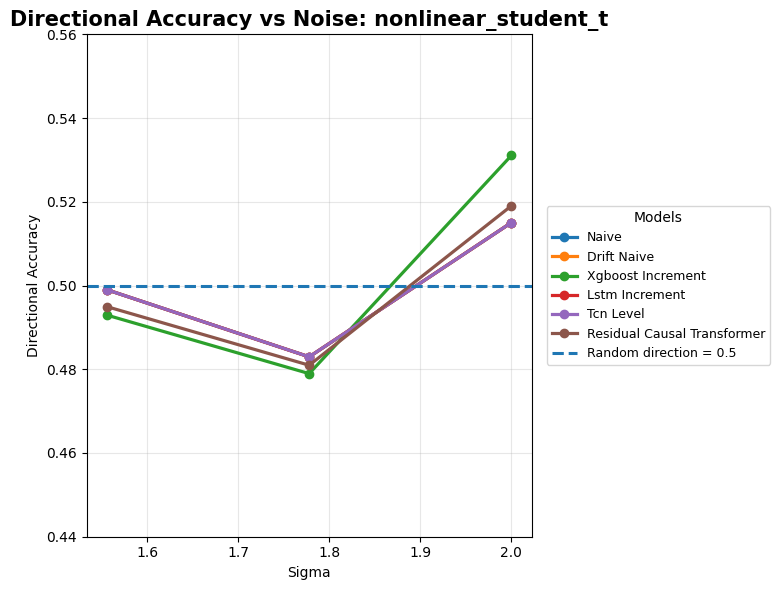

../figures/benchmark_v1_refined\refined_nonlinear_student_t_directional_accuracy_top_models.png


In [22]:
for series in SERIES_ORDER:

    subset = metrics_df[metrics_df["series"] == series]

    plt.figure(figsize=(10, 6))

    for model in TOP_MODELS:
        temp = subset[subset["model"] == model].sort_values("sigma")

        if temp.empty:
            continue

        plt.plot(
            temp["sigma"],
            temp["directional_accuracy"],
            marker="o",
            linewidth=2.3,
            markersize=6,
            label=model_label(model)
        )

    plt.axhline(
        0.5,
        linestyle="--",
        linewidth=2.2,
        label="Random direction = 0.5"
    )

    plt.ylim(0.44, 0.56)

    plt.title(
        f"Directional Accuracy vs Noise: {series}",
        fontsize=15,
        fontweight="bold"
    )
    plt.xlabel("Sigma")
    plt.ylabel("Directional Accuracy")
    plt.grid(True, alpha=0.3)

    plt.legend(
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        ncol=1,
        fontsize=9,
        title="Models",
        title_fontsize=10,
        frameon=True
    )

    plt.tight_layout(rect=[0, 0, 0.78, 1])

    path = os.path.join(
        FIGURE_DIR,
        f"refined_{series}_directional_accuracy_top_models.png"
    )

    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()

    print(path)

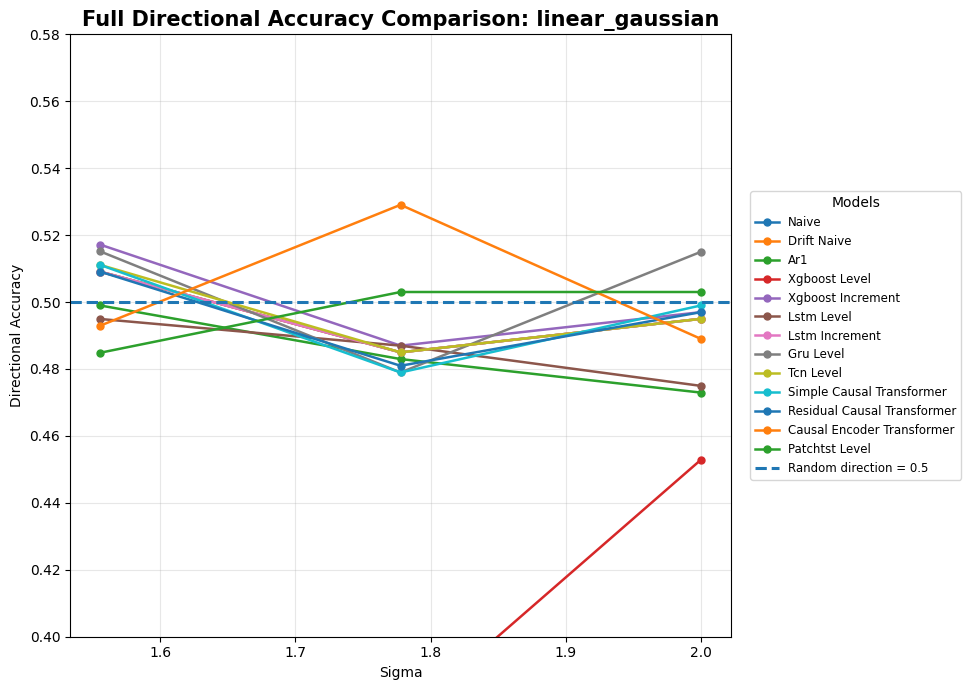

../figures/benchmark_v1_refined\refined_linear_gaussian_directional_accuracy_all_models.png


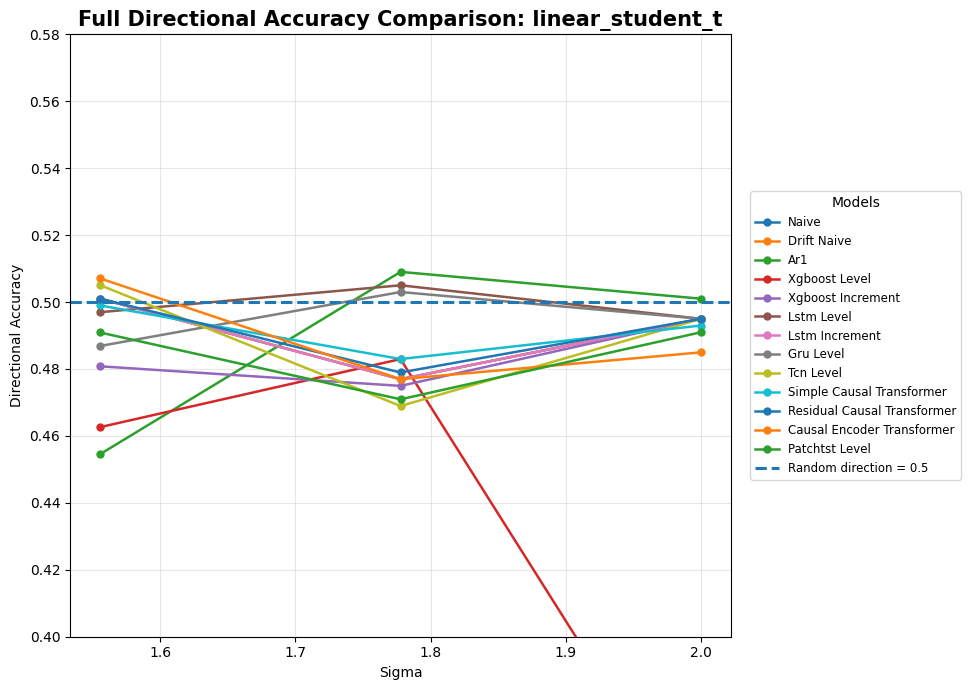

../figures/benchmark_v1_refined\refined_linear_student_t_directional_accuracy_all_models.png


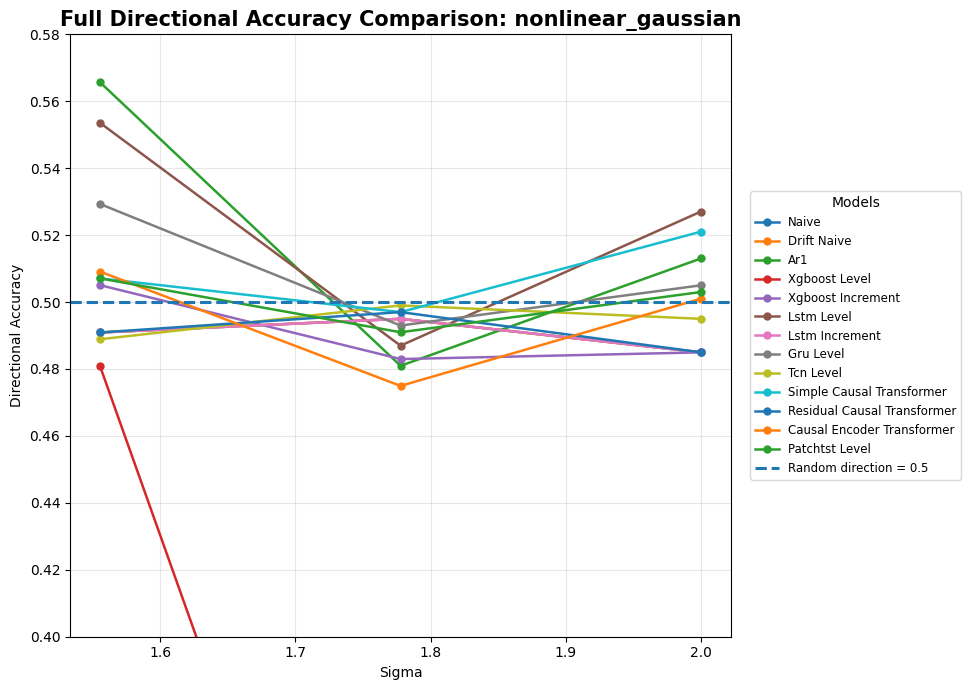

../figures/benchmark_v1_refined\refined_nonlinear_gaussian_directional_accuracy_all_models.png


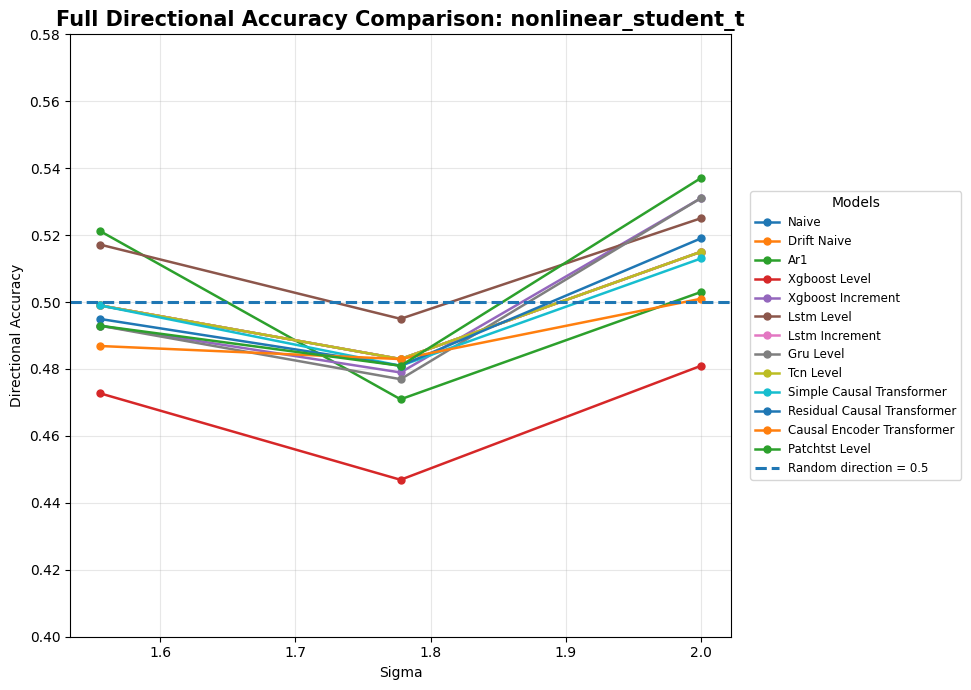

../figures/benchmark_v1_refined\refined_nonlinear_student_t_directional_accuracy_all_models.png


In [23]:
for series in SERIES_ORDER:

    subset = metrics_df[metrics_df["series"] == series]

    plt.figure(figsize=(13, 7))

    for model in MODEL_ORDER:
        temp = subset[subset["model"] == model].sort_values("sigma")

        if temp.empty:
            continue

        plt.plot(
            temp["sigma"],
            temp["directional_accuracy"],
            marker="o",
            linewidth=1.8,
            markersize=5,
            label=model_label(model)
        )

    plt.axhline(
        0.5,
        linestyle="--",
        linewidth=2.2,
        label="Random direction = 0.5"
    )

    plt.ylim(0.40, 0.58)

    plt.title(
        f"Full Directional Accuracy Comparison: {series}",
        fontsize=15,
        fontweight="bold"
    )
    plt.xlabel("Sigma")
    plt.ylabel("Directional Accuracy")
    plt.grid(True, alpha=0.3)

    plt.legend(
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        ncol=1,
        fontsize=8.5,
        title="Models",
        title_fontsize=10,
        frameon=True
    )

    plt.tight_layout(rect=[0, 0, 0.76, 1])

    path = os.path.join(
        FIGURE_DIR,
        f"refined_{series}_directional_accuracy_all_models.png"
    )

    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()

    print(path)

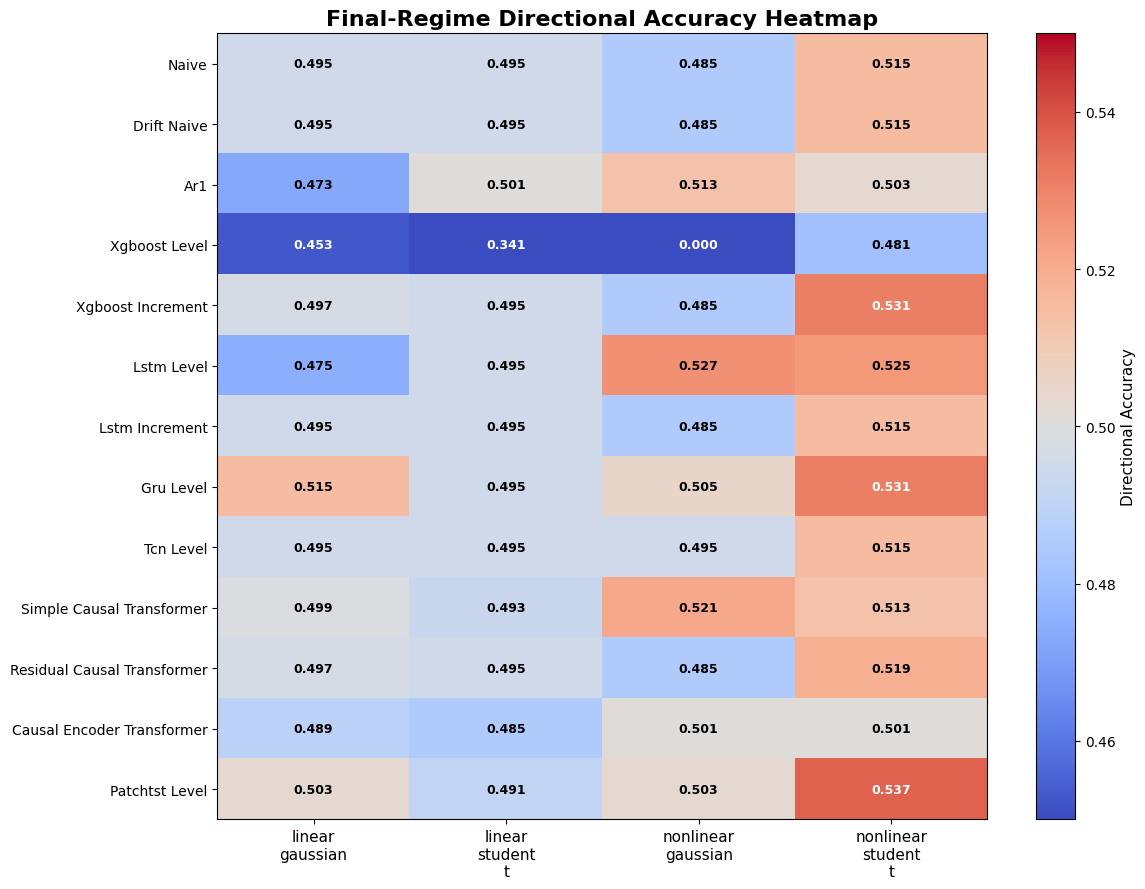

../figures/benchmark_v1_refined\refined_directional_accuracy_heatmap.png


In [24]:
direction_heatmap_df = summary_df.pivot(
    index="model",
    columns="series",
    values="last_directional_accuracy"
).reindex(MODEL_ORDER)

plt.figure(figsize=(12, 9))

im = plt.imshow(
    direction_heatmap_df.values,
    aspect="auto",
    cmap="coolwarm",
    vmin=0.45,
    vmax=0.55
)

plt.xticks(
    ticks=np.arange(len(direction_heatmap_df.columns)),
    labels=[s.replace("_", "\n") for s in direction_heatmap_df.columns],
    rotation=0,
    fontsize=11
)

plt.yticks(
    ticks=np.arange(len(direction_heatmap_df.index)),
    labels=[model_label(m) for m in direction_heatmap_df.index],
    fontsize=10
)

cbar = plt.colorbar(im)
cbar.set_label("Directional Accuracy", fontsize=11)

for i in range(direction_heatmap_df.shape[0]):
    for j in range(direction_heatmap_df.shape[1]):
        value = direction_heatmap_df.values[i, j]

        text_color = "white" if value < 0.47 or value > 0.53 else "black"

        plt.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold",
            color=text_color
        )

plt.title(
    "Final-Regime Directional Accuracy Heatmap",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

path = os.path.join(
    FIGURE_DIR,
    "refined_directional_accuracy_heatmap.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(path)

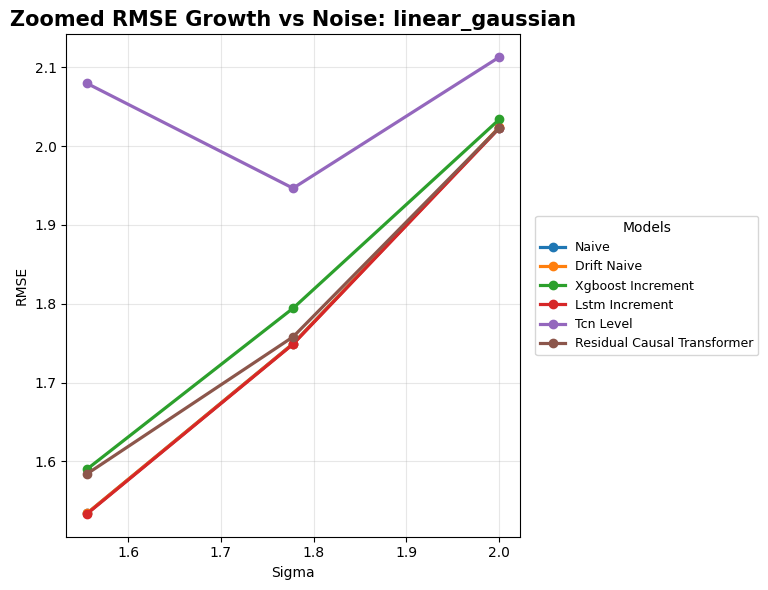

../figures/benchmark_v1_refined\refined_linear_gaussian_rmse_top_models.png


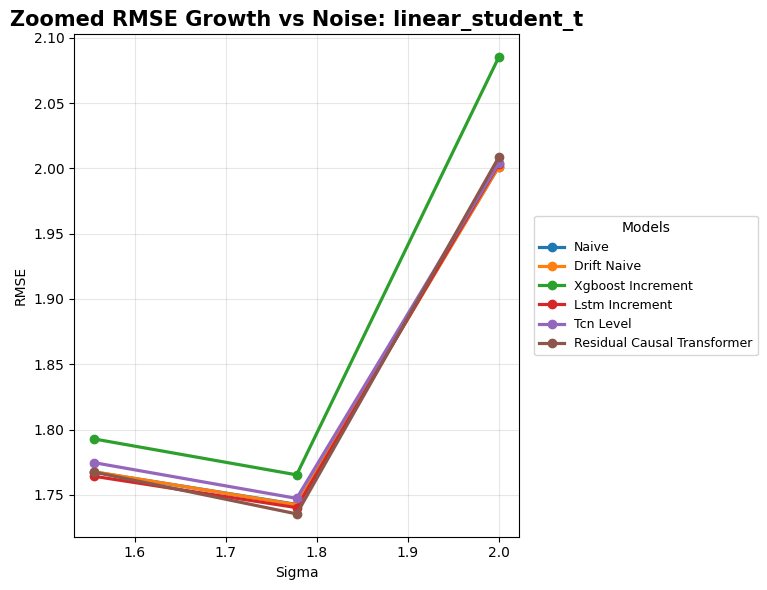

../figures/benchmark_v1_refined\refined_linear_student_t_rmse_top_models.png


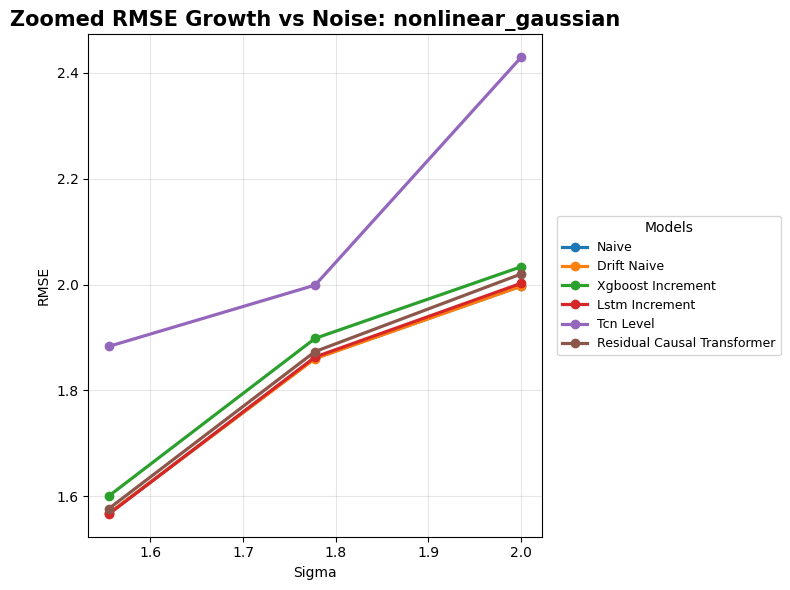

../figures/benchmark_v1_refined\refined_nonlinear_gaussian_rmse_top_models.png


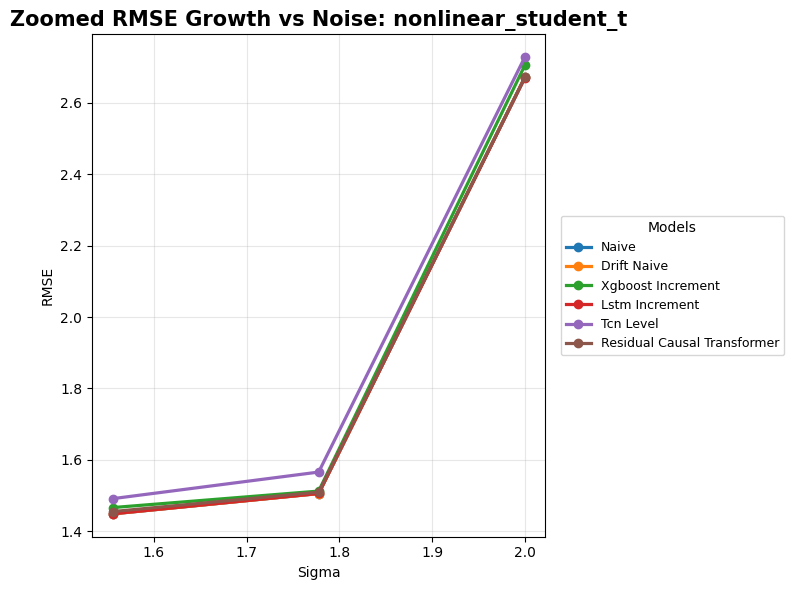

../figures/benchmark_v1_refined\refined_nonlinear_student_t_rmse_top_models.png


In [31]:
for series in SERIES_ORDER:

    subset = metrics_df[metrics_df["series"] == series]

    plt.figure(figsize=(10, 6))

    for model in TOP_MODELS:
        temp = subset[subset["model"] == model].sort_values("sigma")

        if temp.empty:
            continue

        plt.plot(
            temp["sigma"],
            temp["rmse"],
            marker="o",
            linewidth=2.3,
            markersize=6,
            label=model_label(model)
        )

    plt.title(
        f"Zoomed RMSE Growth vs Noise: {series}",
        fontsize=15,
        fontweight="bold"
    )
    plt.xlabel("Sigma")
    plt.ylabel("RMSE")
    plt.grid(True, alpha=0.3)

    plt.legend(
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        ncol=1,
        fontsize=9,
        title="Models",
        title_fontsize=10,
        frameon=True
    )

    plt.tight_layout(rect=[0, 0, 0.78, 1])

    path = os.path.join(
        FIGURE_DIR,
        f"refined_{series}_rmse_top_models.png"
    )

    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()

    print(path)

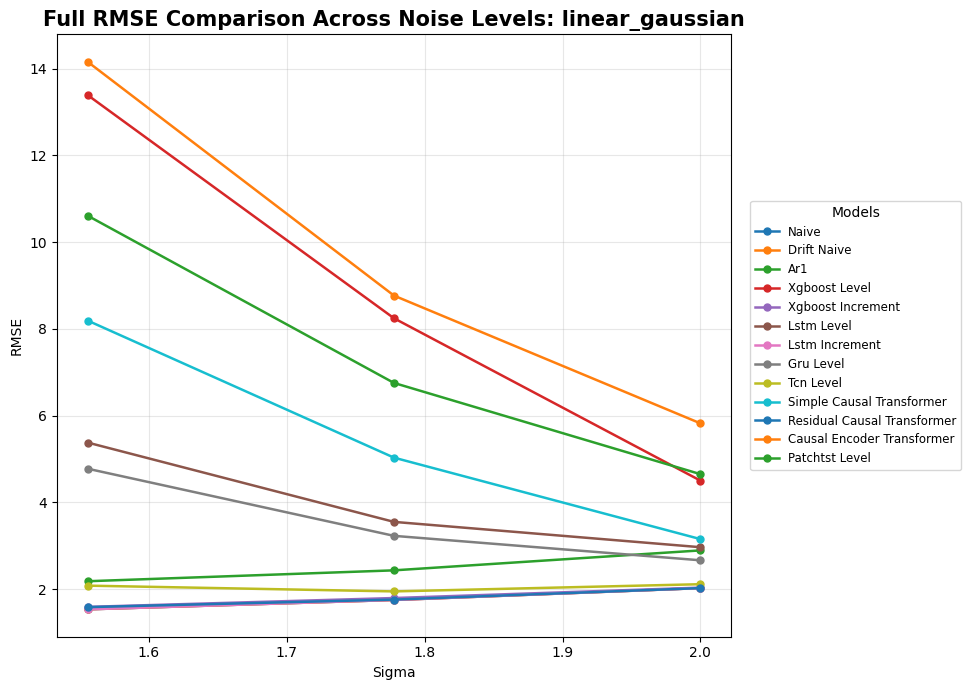

../figures/benchmark_v1_refined\refined_linear_gaussian_rmse_all_models.png


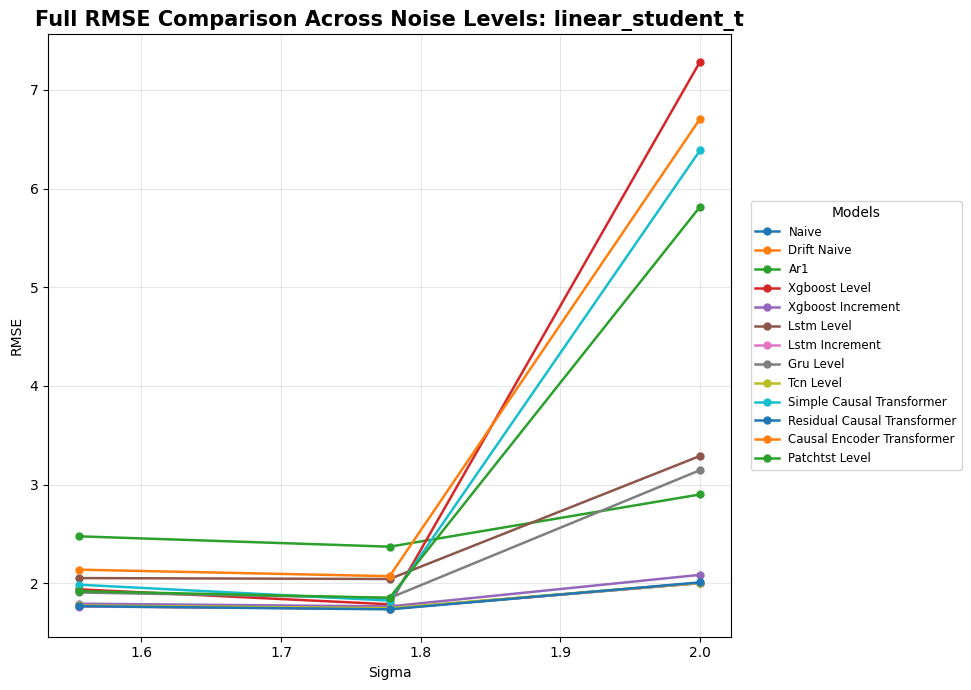

../figures/benchmark_v1_refined\refined_linear_student_t_rmse_all_models.png


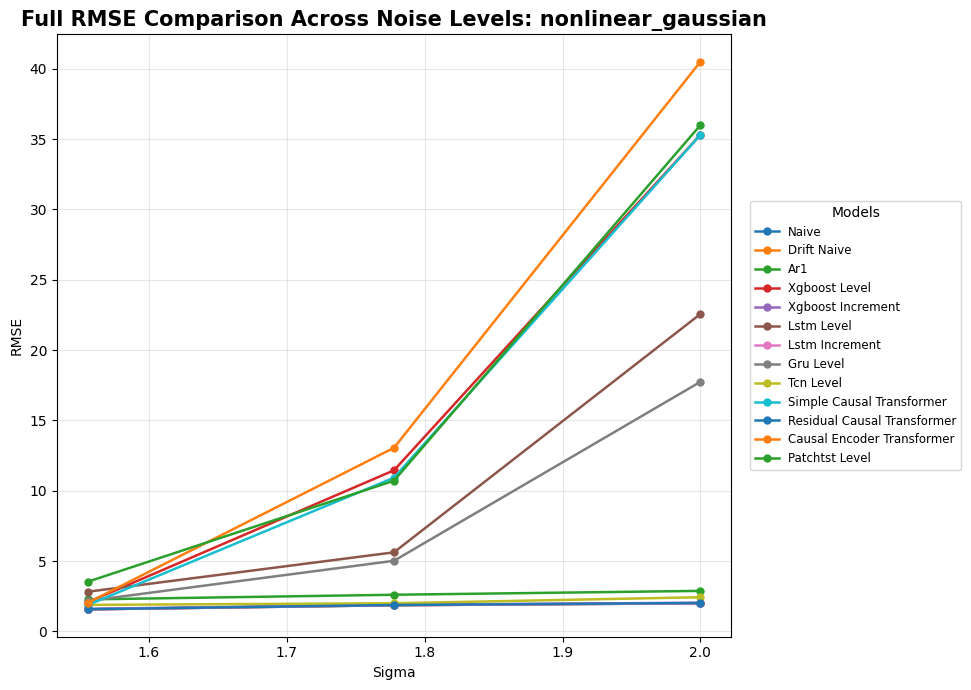

../figures/benchmark_v1_refined\refined_nonlinear_gaussian_rmse_all_models.png


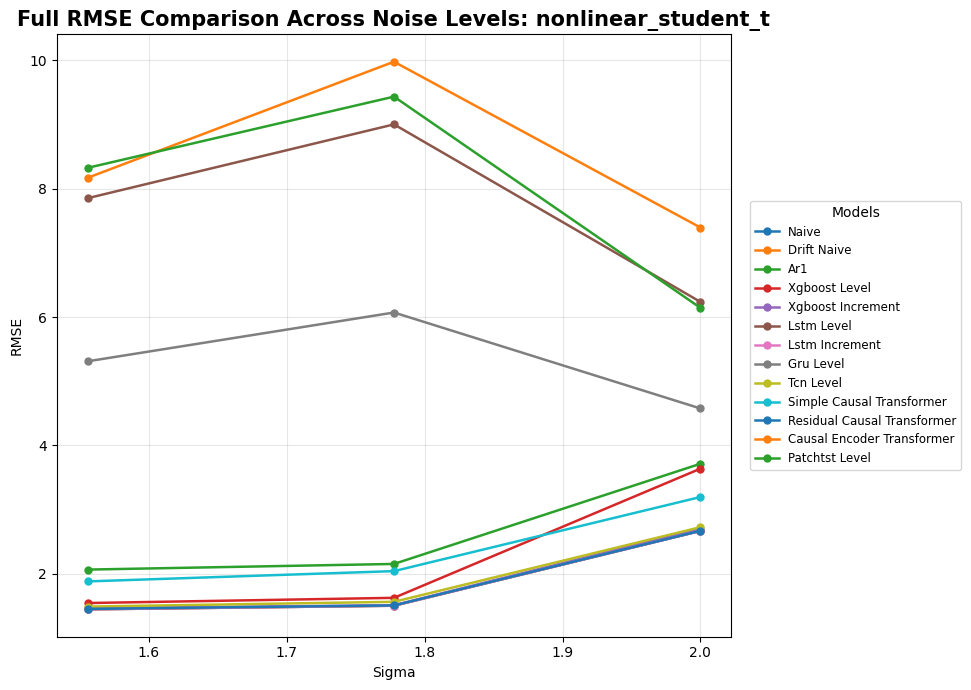

../figures/benchmark_v1_refined\refined_nonlinear_student_t_rmse_all_models.png


In [26]:
for series in SERIES_ORDER:

    subset = metrics_df[metrics_df["series"] == series]

    plt.figure(figsize=(13, 7))

    for model in MODEL_ORDER:
        temp = subset[subset["model"] == model].sort_values("sigma")

        if temp.empty:
            continue

        plt.plot(
            temp["sigma"],
            temp["rmse"],
            marker="o",
            linewidth=1.8,
            markersize=5,
            label=model_label(model)
        )

    plt.title(
        f"Full RMSE Comparison Across Noise Levels: {series}",
        fontsize=15,
        fontweight="bold"
    )
    plt.xlabel("Sigma")
    plt.ylabel("RMSE")
    plt.grid(True, alpha=0.3)

    plt.legend(
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        ncol=1,
        fontsize=8.5,
        title="Models",
        title_fontsize=10,
        frameon=True
    )

    plt.tight_layout(rect=[0, 0, 0.76, 1])

    path = os.path.join(
        FIGURE_DIR,
        f"refined_{series}_rmse_all_models.png"
    )

    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()

    print(path)

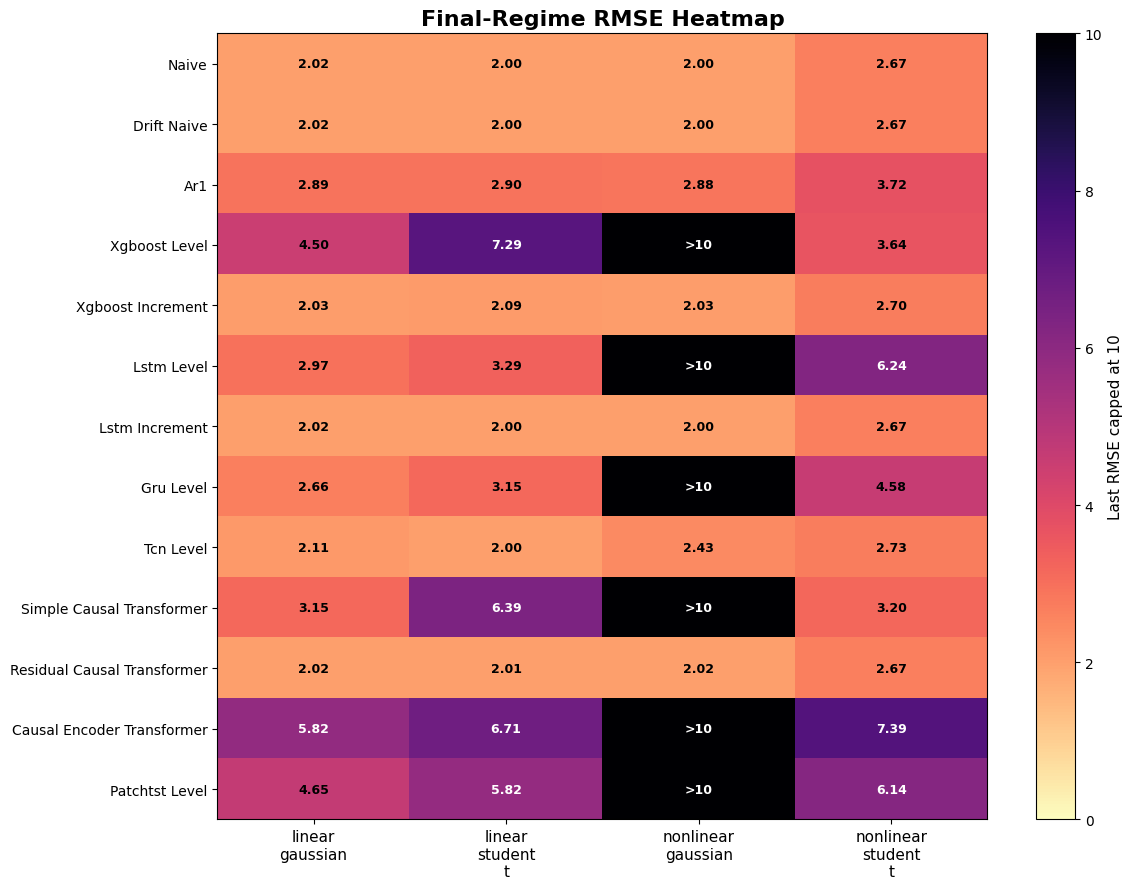

../figures/benchmark_v1_refined\refined_last_rmse_heatmap.png


In [27]:
rmse_heatmap_df = summary_df.pivot(
    index="model",
    columns="series",
    values="last_rmse"
).reindex(MODEL_ORDER)

CAP_VALUE = 10.0
rmse_capped = rmse_heatmap_df.clip(upper=CAP_VALUE)

plt.figure(figsize=(12, 9))

im = plt.imshow(
    rmse_capped.values,
    aspect="auto",
    cmap="magma_r",
    vmin=0,
    vmax=CAP_VALUE
)

plt.xticks(
    ticks=np.arange(len(rmse_capped.columns)),
    labels=[s.replace("_", "\n") for s in rmse_capped.columns],
    rotation=0,
    fontsize=11
)

plt.yticks(
    ticks=np.arange(len(rmse_capped.index)),
    labels=[model_label(m) for m in rmse_capped.index],
    fontsize=10
)

cbar = plt.colorbar(im)
cbar.set_label("Last RMSE capped at 10", fontsize=11)

for i in range(rmse_heatmap_df.shape[0]):
    for j in range(rmse_heatmap_df.shape[1]):
        raw_value = rmse_heatmap_df.values[i, j]

        if raw_value > CAP_VALUE:
            text = f">{CAP_VALUE:.0f}"
        else:
            text = f"{raw_value:.2f}"

        text_color = "white" if rmse_capped.values[i, j] > 5.5 else "black"

        plt.text(
            j,
            i,
            text,
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold",
            color=text_color
        )

plt.title(
    "Final-Regime RMSE Heatmap",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

path = os.path.join(
    FIGURE_DIR,
    "refined_last_rmse_heatmap.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(path)

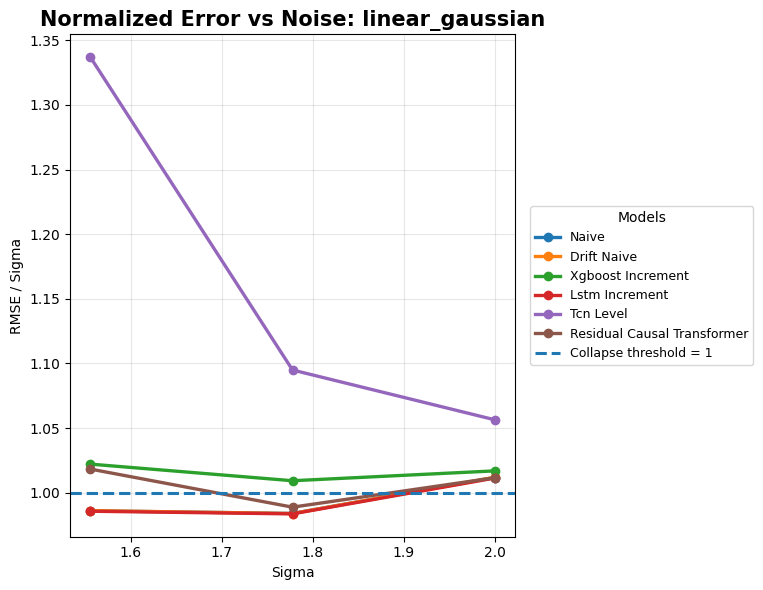

../figures/benchmark_v1_refined\refined_linear_gaussian_rmse_over_sigma_top_models.png


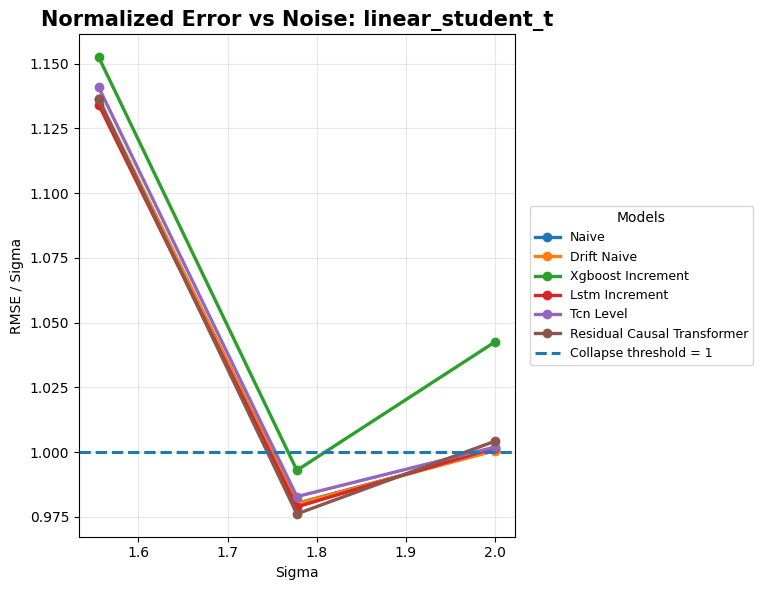

../figures/benchmark_v1_refined\refined_linear_student_t_rmse_over_sigma_top_models.png


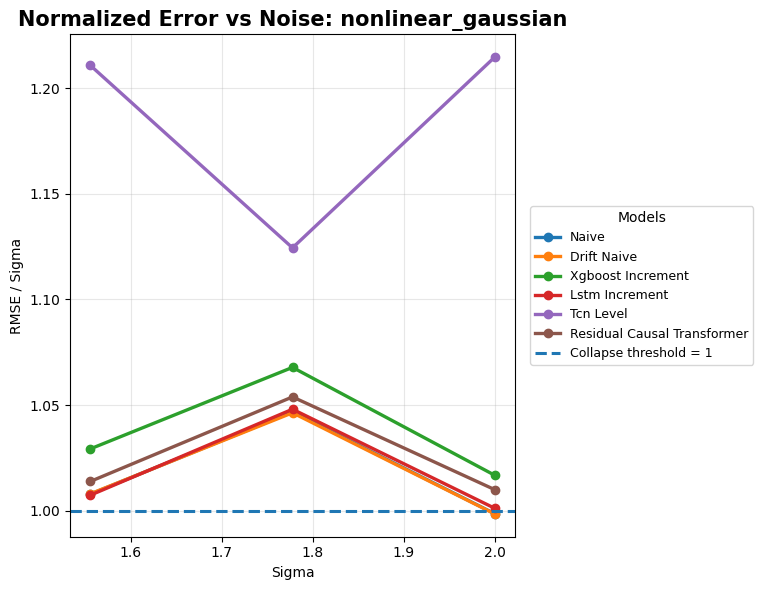

../figures/benchmark_v1_refined\refined_nonlinear_gaussian_rmse_over_sigma_top_models.png


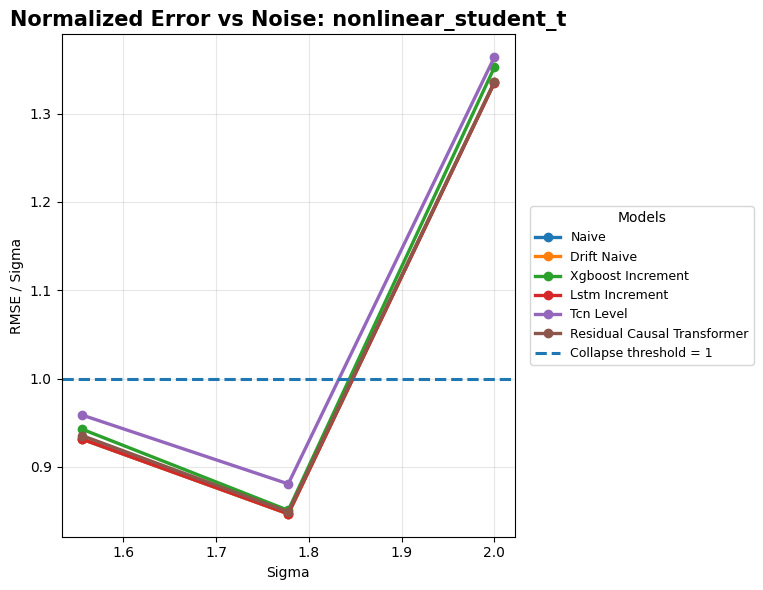

../figures/benchmark_v1_refined\refined_nonlinear_student_t_rmse_over_sigma_top_models.png


In [28]:
for series in SERIES_ORDER:

    subset = metrics_df[metrics_df["series"] == series]

    plt.figure(figsize=(10, 6))

    for model in TOP_MODELS:
        temp = subset[subset["model"] == model].sort_values("sigma")

        if temp.empty:
            continue

        plt.plot(
            temp["sigma"],
            temp["rmse_over_sigma"],
            marker="o",
            linewidth=2.4,
            markersize=6,
            label=model_label(model)
        )

    plt.axhline(
        1.0,
        linestyle="--",
        linewidth=2.2,
        label="Collapse threshold = 1"
    )

    plt.title(
        f"Normalized Error vs Noise: {series}",
        fontsize=15,
        fontweight="bold"
    )
    plt.xlabel("Sigma")
    plt.ylabel("RMSE / Sigma")
    plt.grid(True, alpha=0.3)

    plt.legend(
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        ncol=1,
        fontsize=9,
        title="Models",
        title_fontsize=10,
        frameon=True
    )

    plt.tight_layout(rect=[0, 0, 0.78, 1])

    path = os.path.join(
        FIGURE_DIR,
        f"refined_{series}_rmse_over_sigma_top_models.png"
    )

    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()

    print(path)

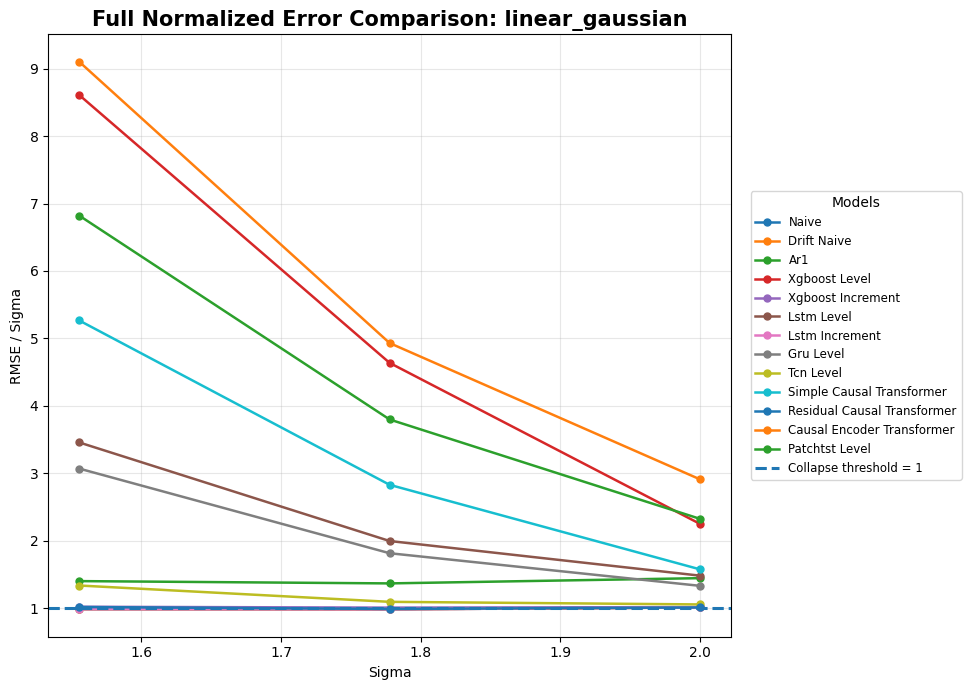

../figures/benchmark_v1_refined\refined_linear_gaussian_rmse_over_sigma_all_models.png


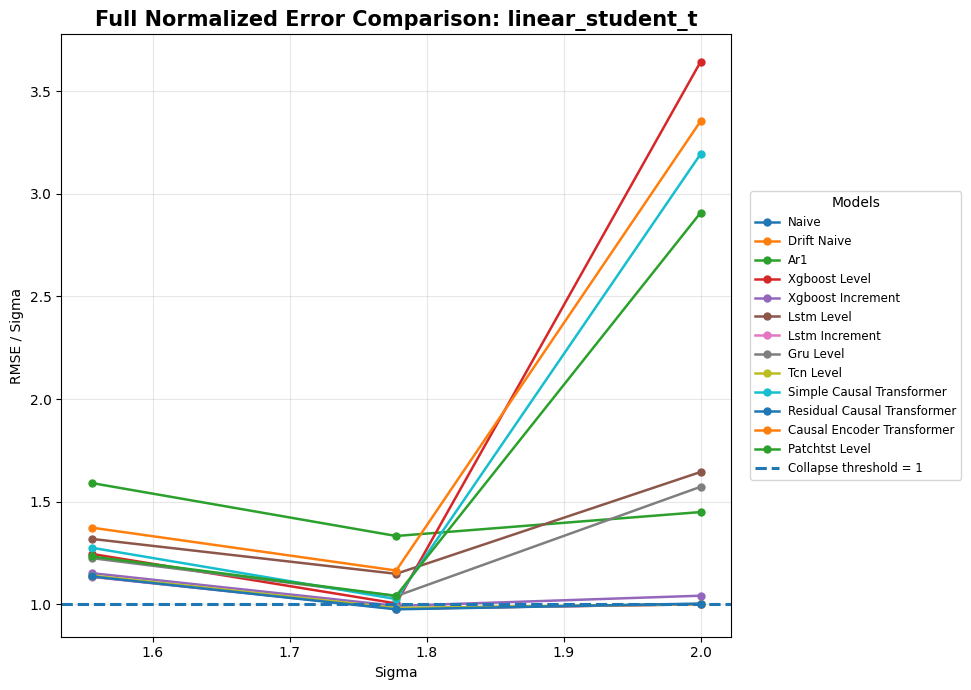

../figures/benchmark_v1_refined\refined_linear_student_t_rmse_over_sigma_all_models.png


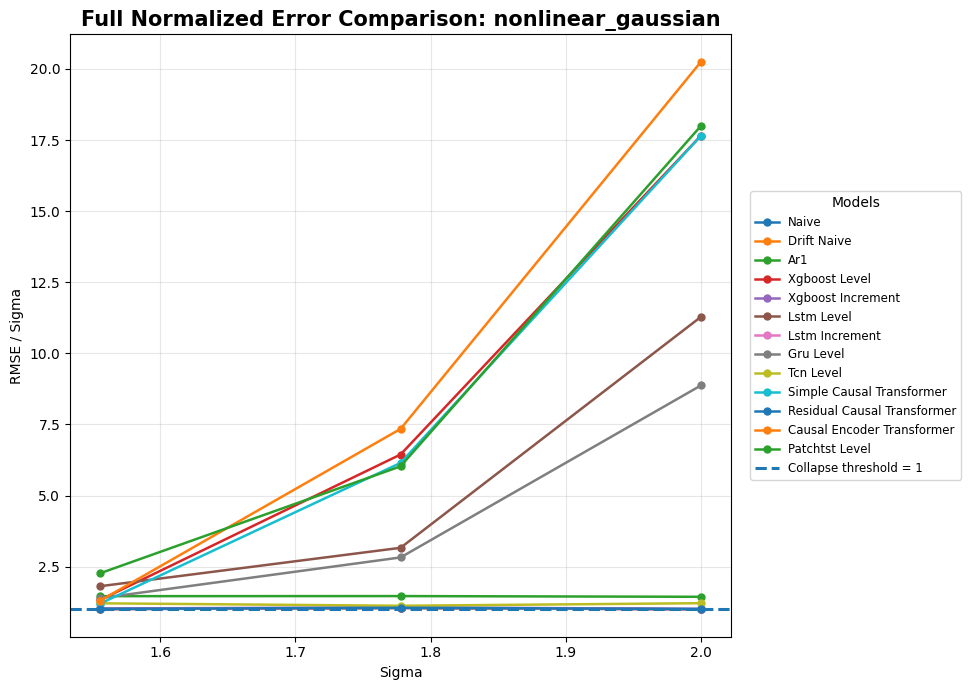

../figures/benchmark_v1_refined\refined_nonlinear_gaussian_rmse_over_sigma_all_models.png


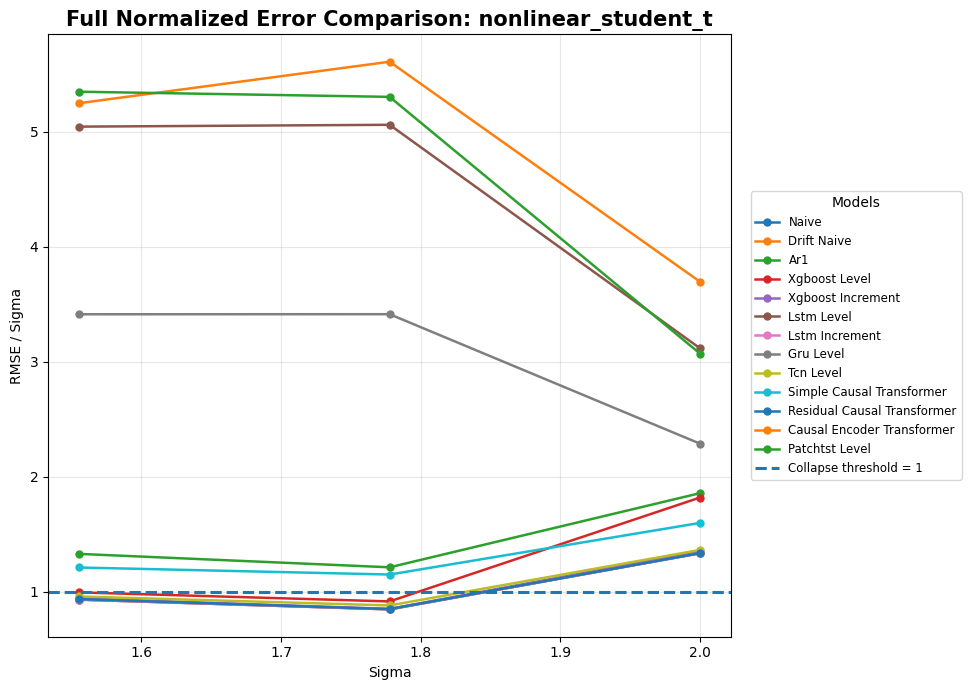

../figures/benchmark_v1_refined\refined_nonlinear_student_t_rmse_over_sigma_all_models.png


In [29]:
for series in SERIES_ORDER:

    subset = metrics_df[metrics_df["series"] == series]

    plt.figure(figsize=(13, 7))

    for model in MODEL_ORDER:
        temp = subset[subset["model"] == model].sort_values("sigma")

        if temp.empty:
            continue

        plt.plot(
            temp["sigma"],
            temp["rmse_over_sigma"],
            marker="o",
            linewidth=1.8,
            markersize=5,
            label=model_label(model)
        )

    plt.axhline(
        1.0,
        linestyle="--",
        linewidth=2.2,
        label="Collapse threshold = 1"
    )

    plt.title(
        f"Full Normalized Error Comparison: {series}",
        fontsize=15,
        fontweight="bold"
    )
    plt.xlabel("Sigma")
    plt.ylabel("RMSE / Sigma")
    plt.grid(True, alpha=0.3)

    plt.legend(
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        ncol=1,
        fontsize=8.5,
        title="Models",
        title_fontsize=10,
        frameon=True
    )

    plt.tight_layout(rect=[0, 0, 0.76, 1])

    path = os.path.join(
        FIGURE_DIR,
        f"refined_{series}_rmse_over_sigma_all_models.png"
    )

    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()

    print(path)

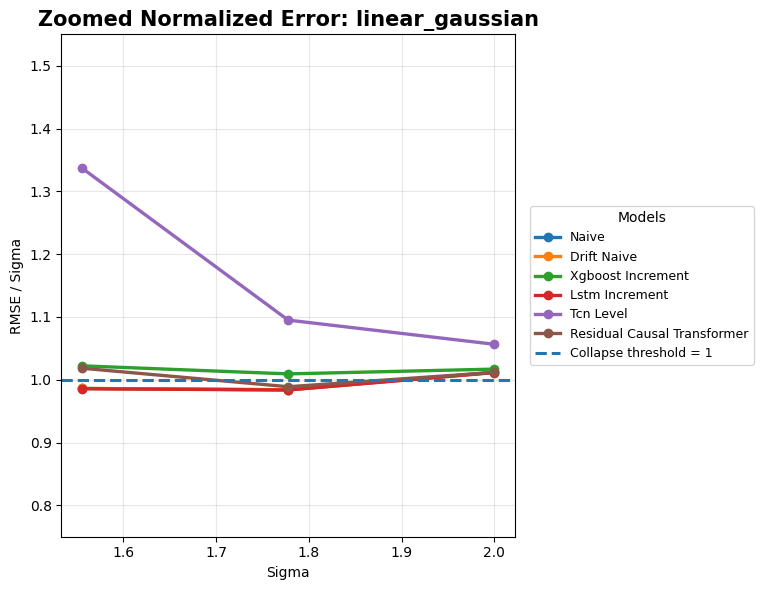

../figures/benchmark_v1_refined\refined_linear_gaussian_rmse_over_sigma_zoomed_top_models.png


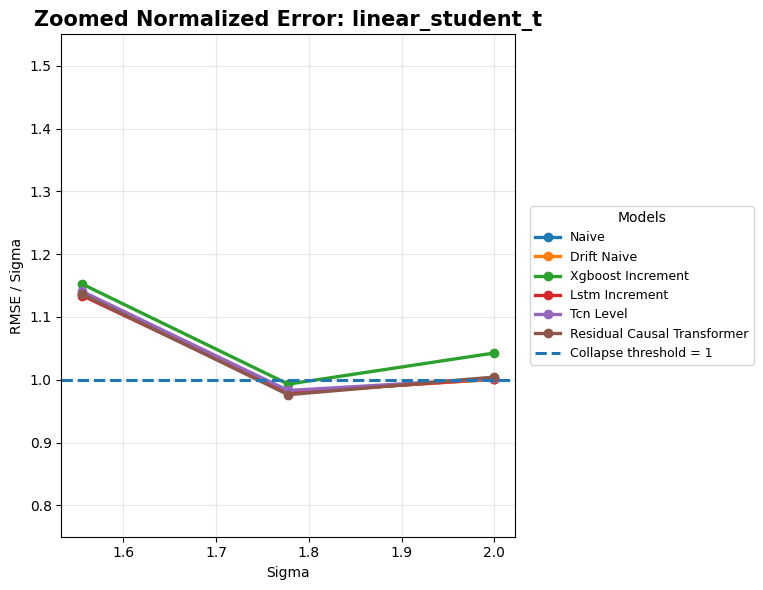

../figures/benchmark_v1_refined\refined_linear_student_t_rmse_over_sigma_zoomed_top_models.png


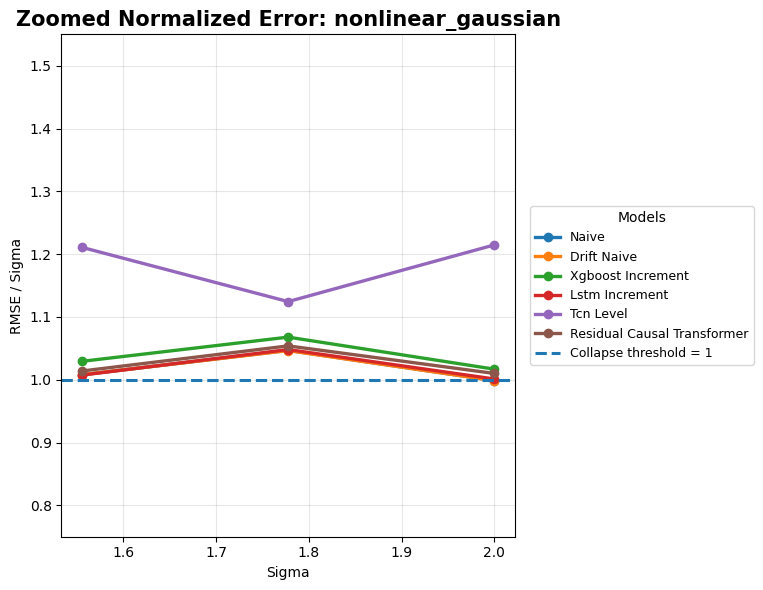

../figures/benchmark_v1_refined\refined_nonlinear_gaussian_rmse_over_sigma_zoomed_top_models.png


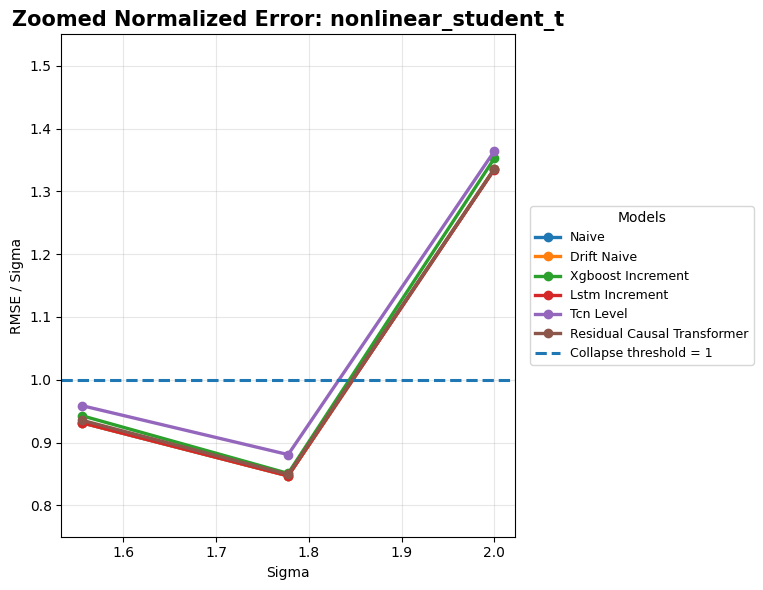

../figures/benchmark_v1_refined\refined_nonlinear_student_t_rmse_over_sigma_zoomed_top_models.png


In [30]:
for series in SERIES_ORDER:

    subset = metrics_df[metrics_df["series"] == series]

    plt.figure(figsize=(10, 6))

    for model in TOP_MODELS:
        temp = subset[subset["model"] == model].sort_values("sigma")

        if temp.empty:
            continue

        plt.plot(
            temp["sigma"],
            temp["rmse_over_sigma"],
            marker="o",
            linewidth=2.4,
            markersize=6,
            label=model_label(model)
        )

    plt.axhline(
        1.0,
        linestyle="--",
        linewidth=2.2,
        label="Collapse threshold = 1"
    )

    plt.ylim(0.75, 1.55)

    plt.title(
        f"Zoomed Normalized Error: {series}",
        fontsize=15,
        fontweight="bold"
    )
    plt.xlabel("Sigma")
    plt.ylabel("RMSE / Sigma")
    plt.grid(True, alpha=0.3)

    plt.legend(
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        ncol=1,
        fontsize=9,
        title="Models",
        title_fontsize=10,
        frameon=True
    )

    plt.tight_layout(rect=[0, 0, 0.78, 1])

    path = os.path.join(
        FIGURE_DIR,
        f"refined_{series}_rmse_over_sigma_zoomed_top_models.png"
    )

    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()

    print(path)

In [32]:
def collapse_to_numeric(x):
    if isinstance(x, str) and ">" in x:
        return 2.05
    try:
        return float(x)
    except Exception:
        return np.nan


collapse_df = summary_df.copy()

collapse_df["collapse_numeric"] = collapse_df["collapse_sigma"].apply(
    collapse_to_numeric
)

collapse_df["collapse_label"] = collapse_df["collapse_sigma"].astype(str)

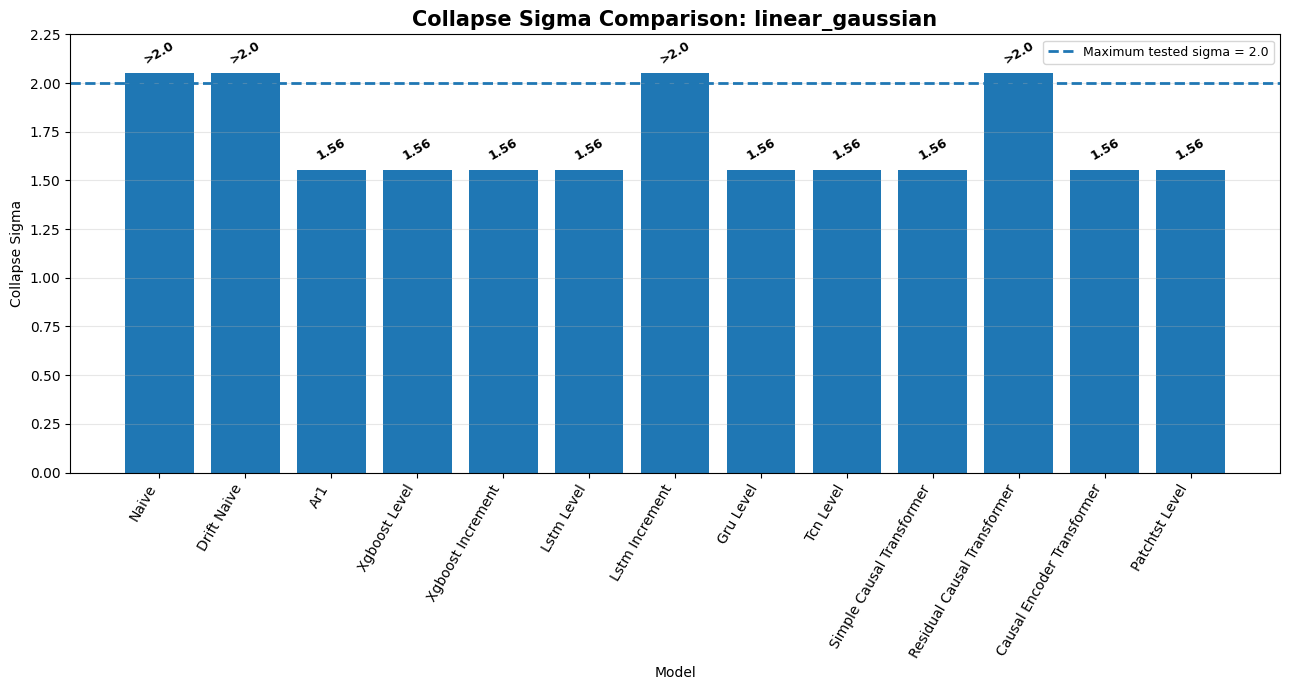

../figures/benchmark_v1_refined\refined_linear_gaussian_collapse_sigma_comparison.png


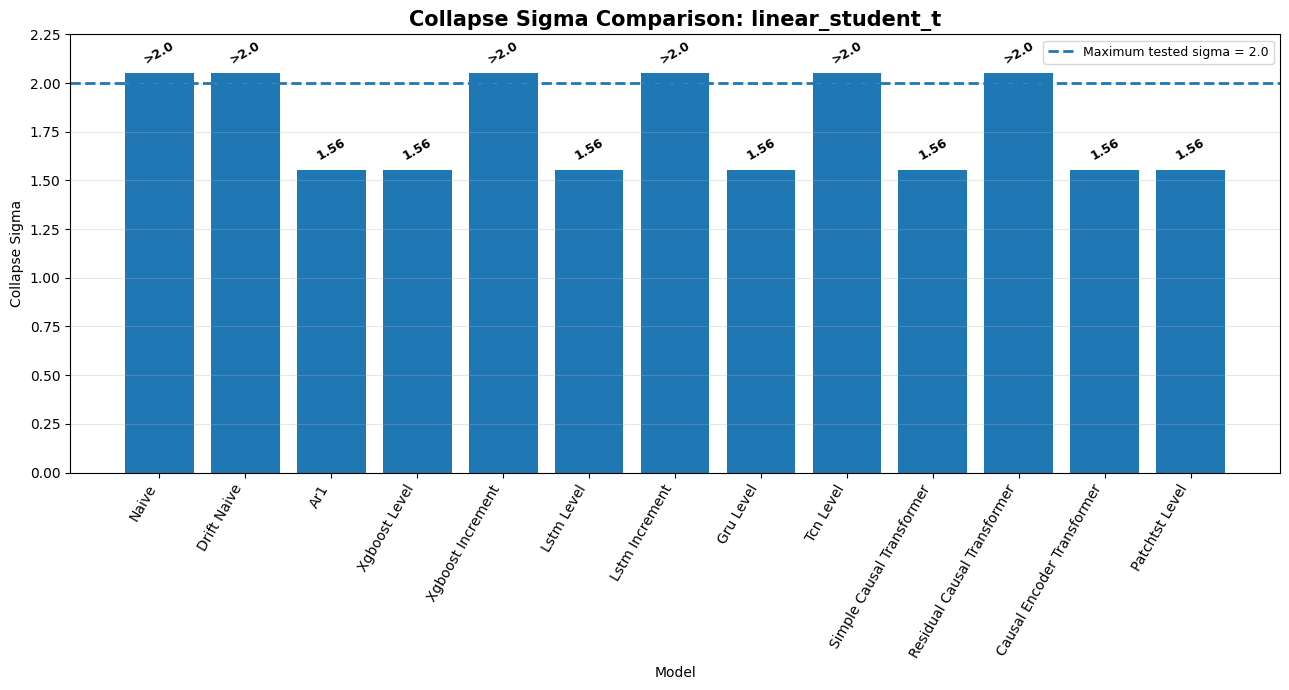

../figures/benchmark_v1_refined\refined_linear_student_t_collapse_sigma_comparison.png


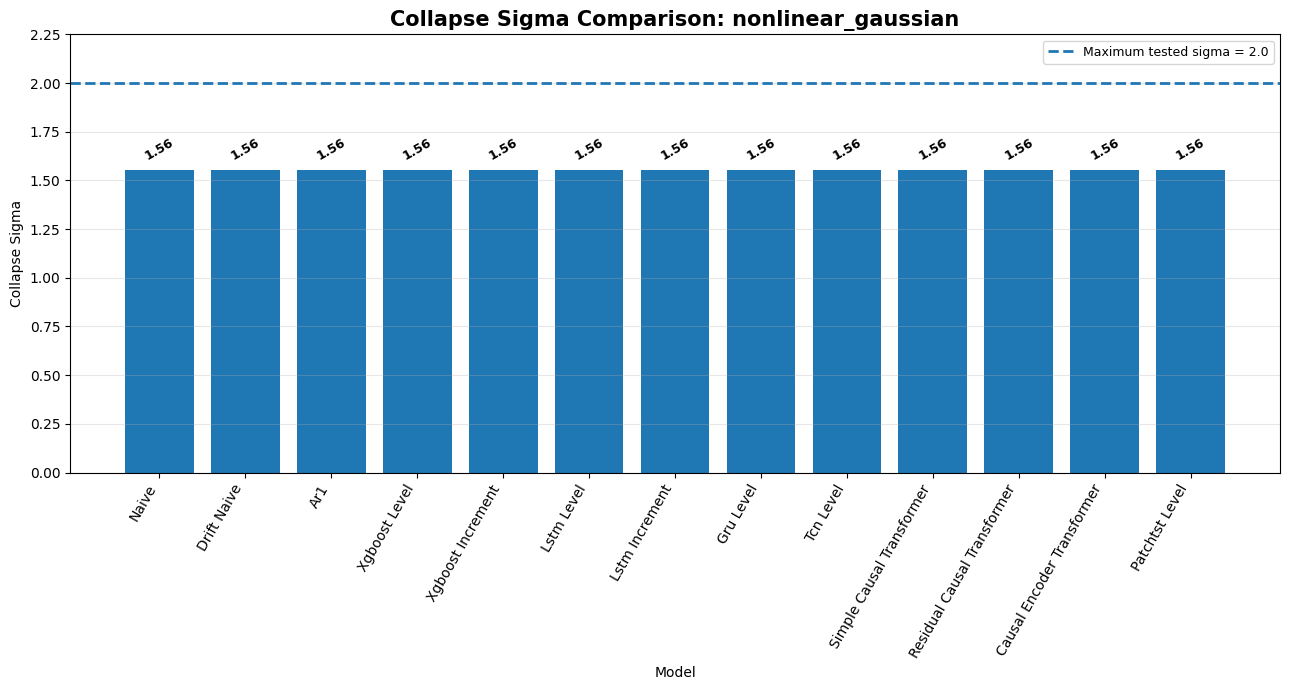

../figures/benchmark_v1_refined\refined_nonlinear_gaussian_collapse_sigma_comparison.png


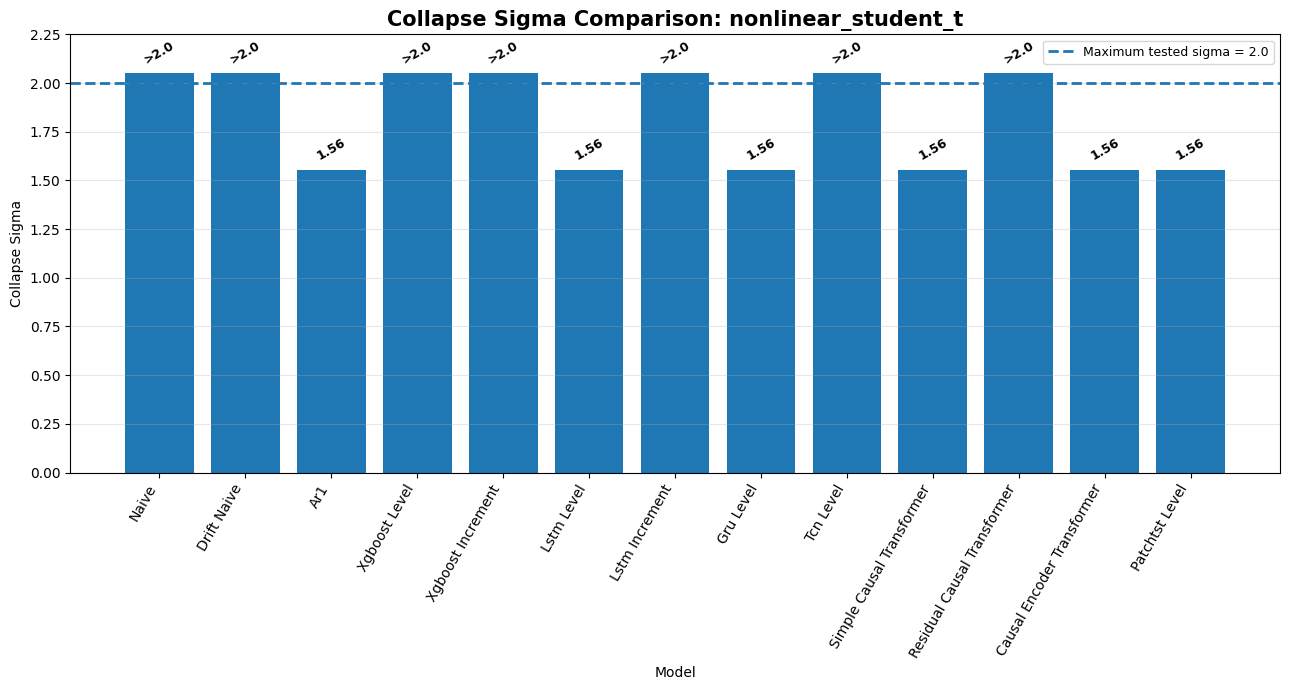

../figures/benchmark_v1_refined\refined_nonlinear_student_t_collapse_sigma_comparison.png


In [35]:
for series in SERIES_ORDER:

    subset = collapse_df[collapse_df["series"] == series].copy()

    subset["model"] = pd.Categorical(
        subset["model"],
        categories=MODEL_ORDER,
        ordered=True
    )

    subset = subset.sort_values("model")

    plt.figure(figsize=(13, 7))

    bars = plt.bar(
        [model_label(m) for m in subset["model"]],
        subset["collapse_numeric"]
    )

    plt.axhline(
        2.0,
        linestyle="--",
        linewidth=2,
        label="Maximum tested sigma = 2.0"
    )

    for bar, label in zip(bars, subset["collapse_label"]):

        if ">" in label:
            text = ">2.0"
        else:
            text = f"{float(label):.2f}"

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.035,
            text,
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            rotation=30
        )

    plt.ylim(0, 2.25)

    plt.title(
        f"Collapse Sigma Comparison: {series}",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel("Model")
    plt.ylabel("Collapse Sigma")
    plt.xticks(rotation=60, ha="right")
    plt.grid(axis="y", alpha=0.3)

    plt.legend(
        loc="upper right",
        fontsize=9,
        frameon=True
    )

    plt.tight_layout()

    path = os.path.join(
        FIGURE_DIR,
        f"refined_{series}_collapse_sigma_comparison.png"
    )

    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()

    print(path)

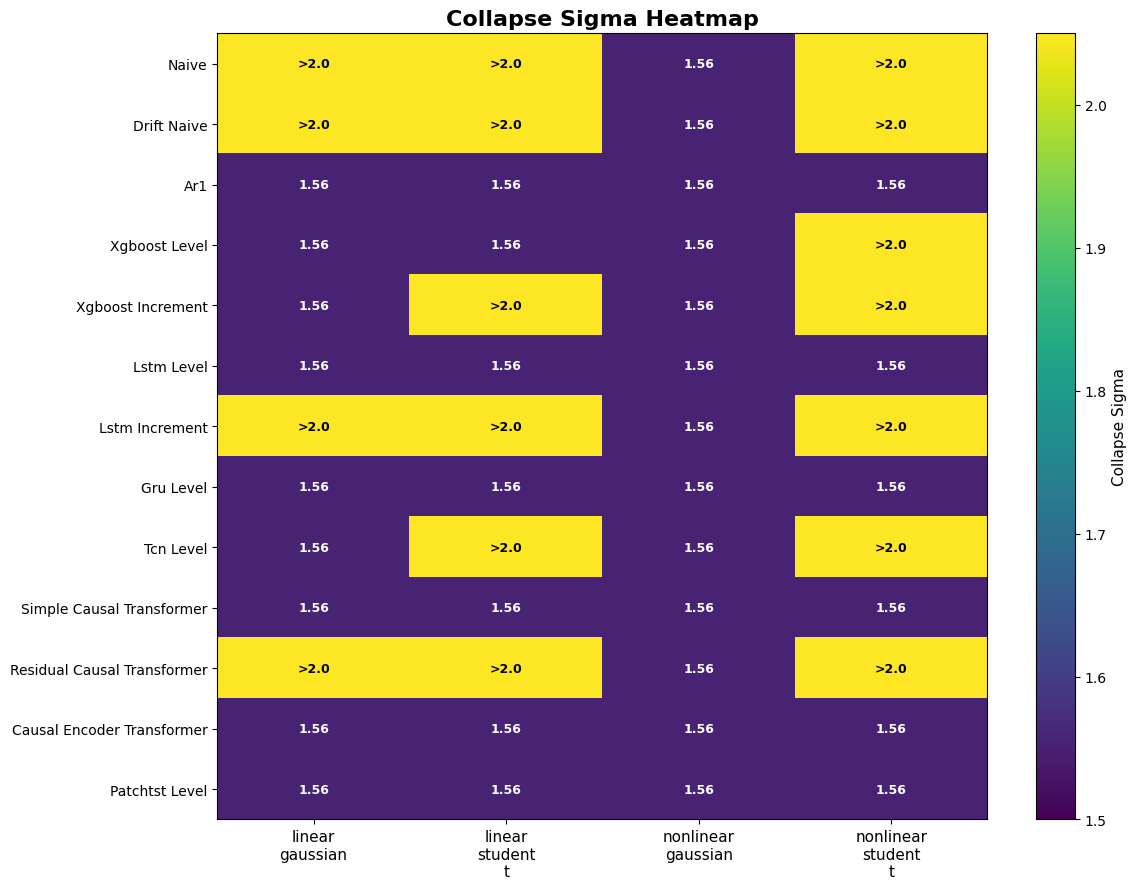

../figures/benchmark_v1_refined\refined_collapse_sigma_heatmap.png


In [36]:
collapse_heatmap_df = collapse_df.pivot(
    index="model",
    columns="series",
    values="collapse_numeric"
).reindex(MODEL_ORDER)

plt.figure(figsize=(12, 9))

im = plt.imshow(
    collapse_heatmap_df.values,
    aspect="auto",
    cmap="viridis",
    vmin=1.5,
    vmax=2.05
)

plt.xticks(
    ticks=np.arange(len(collapse_heatmap_df.columns)),
    labels=[s.replace("_", "\n") for s in collapse_heatmap_df.columns],
    rotation=0,
    fontsize=11
)

plt.yticks(
    ticks=np.arange(len(collapse_heatmap_df.index)),
    labels=[model_label(m) for m in collapse_heatmap_df.index],
    fontsize=10
)

cbar = plt.colorbar(im)
cbar.set_label("Collapse Sigma", fontsize=11)

for i in range(collapse_heatmap_df.shape[0]):
    for j in range(collapse_heatmap_df.shape[1]):

        value = collapse_heatmap_df.values[i, j]

        original = collapse_df[
            (collapse_df["model"] == collapse_heatmap_df.index[i])
            & (collapse_df["series"] == collapse_heatmap_df.columns[j])
        ]["collapse_sigma"].iloc[0]

        if isinstance(original, str) and ">" in original:
            text = ">2.0"
        else:
            text = f"{value:.2f}"

        text_color = "white" if value < 1.75 else "black"

        plt.text(
            j,
            i,
            text,
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold",
            color=text_color
        )

plt.title(
    "Collapse Sigma Heatmap",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

path = os.path.join(
    FIGURE_DIR,
    "refined_collapse_sigma_heatmap.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(path)